# T20 Cricket Match Score Prediction Using Advanced Machine Learning and Ensemble Learning

**Task:** supervised regression · **Target:** `Predicted Score` · **Dataset:** `t20_cricket_match_score_prediction.csv` ([Kaggle: zeeshier/t20-cricket-match-score-dataset](https://www.kaggle.com/datasets/zeeshier/t20-cricket-match-score-dataset))

This notebook runs top to bottom in Google Colab. It loads the CSV, audits the data, runs EDA, builds a leakage-safe scikit-learn pipeline, compares 11 regressors plus Voting and Stacking ensembles, tunes the strongest ones, picks one model on validation/cross-validation only, evaluates it **once** on an untouched test set, explains it, builds an interactive predictor and exports everything.

**Honesty rules used throughout:** every metric is computed from real predictions in this run; no accuracy target is promised; the test set is used only once, at the end; Match ID is never a feature.

**How to run (Google Colab):** upload/clone the project so the notebook sits next to `dataset/`, then `Runtime -> Run all`. The dataset loader tries, in order: the local `dataset/` folder, Google Drive (`USE_GOOGLE_DRIVE = True`), a Kaggle download (`USE_KAGGLE_DOWNLOAD = True`) and finally a Colab file-upload prompt. See Section 2 for details.

**Reproducibility:** exact library versions are in `requirements.txt` / `runtime_versions.json`; Section 1A compares them with the current runtime. Seeds are fixed (`SEED = 42`). Please also read **Section 3A, Dataset Limitations and Experimental Considerations**, before interpreting any metric.

## 1. Setup: libraries, configuration, helpers
Installs only optional packages that are missing, imports everything, and fixes the random seed for reproducibility.

In [1]:
import os, sys, json, time, shutil, zipfile, warnings, importlib, subprocess
warnings.filterwarnings("ignore")

def ensure_package(import_name, pip_name=None):
    """Import a package, installing it quietly only if missing. Returns True when usable."""
    try:
        importlib.import_module(import_name); return True
    except ImportError:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or import_name],
                                  stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
            importlib.invalidate_caches(); importlib.import_module(import_name); return True
        except Exception as e:
            print(f"[skip] optional package '{import_name}' unavailable ({type(e).__name__}).")
            return False

HAS_XGB  = ensure_package("xgboost")
HAS_LGBM = ensure_package("lightgbm")
HAS_CAT  = ensure_package("catboost")
HAS_OPT  = ensure_package("optuna")
HAS_SHAP = ensure_package("shap")
HAS_WIDGETS = ensure_package("ipywidgets")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from scipy import stats
from scipy.stats import randint, uniform, loguniform

from sklearn.model_selection import (train_test_split, KFold, cross_val_score, cross_validate,
                                     cross_val_predict, RandomizedSearchCV, GridSearchCV, learning_curve)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, VotingRegressor, StackingRegressor)
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, explained_variance_score)
if HAS_XGB:  from xgboost import XGBRegressor
if HAS_LGBM: from lightgbm import LGBMRegressor
if HAS_CAT:  from catboost import CatBoostRegressor
if HAS_OPT:
    import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)

try:
    from google.colab import files, drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})

DATASET_DIR, MODELS_DIR, RESULTS_DIR, VIZ_DIR = "dataset", "models", "results", "visualizations"
for _d in (DATASET_DIR, MODELS_DIR, RESULTS_DIR, VIZ_DIR):
    os.makedirs(_d, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(os.path.join(VIZ_DIR, name), dpi=150, bbox_inches="tight")

print("Environment ready | Colab:", IN_COLAB, "| XGBoost:", HAS_XGB, "| LightGBM:", HAS_LGBM,
      "| CatBoost:", HAS_CAT, "| Optuna:", HAS_OPT, "| SHAP:", HAS_SHAP, "| ipywidgets:", HAS_WIDGETS)

Matplotlib is building the font cache; this may take a moment.


Environment ready | Colab: False | XGBoost: True | LightGBM: True | CatBoost: True | Optuna: True | SHAP: True | ipywidgets: True


## 1A. Runtime environment verification
Compares the libraries in this session with the versions the saved models were trained with (`runtime_versions.json`, also listed in `requirements.txt`). The saved pickles were produced with scikit-learn 1.9.1 / NumPy 2.5.4 / pandas 3.0.6 on Python 3.12.3. **Pickles are not guaranteed to load on other scikit-learn versions**: if you see mismatches below, either install the pinned versions (`pip install -r requirements.txt`, then restart the runtime) or simply re-run this notebook, which retrains and regenerates every artifact with the versions in your session.

In [2]:
from importlib import metadata as _md
PACKAGES = ["numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "seaborn", "xgboost", "lightgbm", "catboost", "shap", "joblib", "optuna", "ipywidgets"]
def _ver(p):
    try: return _md.version(p)
    except _md.PackageNotFoundError: return None
runtime_now = {"python": sys.version.split()[0], **{p: _ver(p) for p in PACKAGES}}
pinned = None
for _p in ("runtime_versions.json", "../runtime_versions.json", "/content/runtime_versions.json"):
    if os.path.exists(_p):
        with open(_p) as _f: pinned = json.load(_f).get("packages_and_python", None); break
rows = []
for k, v in runtime_now.items():
    ref = (pinned or {}).get(k)
    status = "n/a (no pinned file)" if pinned is None else ("OK" if ref == v else ("not installed" if v is None else "DIFFERENT"))
    rows.append({"package": k, "this session": v, "training environment": ref, "status": status})
version_table = pd.DataFrame(rows); display(version_table)
if pinned is not None and (version_table["status"] != "OK").any():
    print("NOTE: versions differ from the training environment. Metrics are regenerated by this notebook, but loading the PRE-SAVED pickles "
          "from models/ may fail or warn on a different scikit-learn version. Fix: pip install -r requirements.txt (then restart runtime).")

,package,this session,training environment,status
0,python,3.12.10,3.12.3,DIFFERENT
1,numpy,2.5.4,2.5.4,OK
2,pandas,3.0.6,3.0.6,OK
3,scikit-learn,1.9.1,1.9.1,OK
4,scipy,1.18.1,1.18.1,OK
5,matplotlib,3.11.2,3.11.2,OK
6,seaborn,0.13.2,0.13.2,OK
7,xgboost,3.4.1,3.4.1,OK
8,lightgbm,4.7.0,4.7.0,OK
9,catboost,1.2.10,1.2.10,OK


NOTE: versions differ from the training environment. Metrics are regenerated by this notebook, but loading the PRE-SAVED pickles from models/ may fail or warn on a different scikit-learn version. Fix: pip install -r requirements.txt (then restart runtime).


## 2. Dataset acquisition and loading
The original CSV is included at `dataset/t20_cricket_match_score_prediction.csv`. Source: [Kaggle: zeeshier/t20-cricket-match-score-dataset](https://www.kaggle.com/datasets/zeeshier/t20-cricket-match-score-dataset). No other dataset is ever substituted.

The loader tries, in this order, and stops at the first success:
1. **Local file:** `dataset/`, the working directory, or `/content` (Colab).
2. **Google Drive:** set `USE_GOOGLE_DRIVE = True` and `DRIVE_PATH`.
3. **Kaggle download:** set `USE_KAGGLE_DOWNLOAD = True` (needs Kaggle access in your environment, e.g. `KAGGLE_USERNAME`/`KAGGLE_KEY` or `kagglehub.login()`).
4. **Colab upload:** an upload prompt appears; the file name must be `t20_cricket_match_score_prediction.csv`.

Whatever the source, the **file name and required columns are validated**, and a clear error explains what to do if the data is unavailable. The Kaggle and Drive routes could not be exercised in the environment where this notebook was prepared (no Kaggle/Drive access), so they are provided as documented alternatives.

In [3]:
DATA_FILE = "t20_cricket_match_score_prediction.csv"
KAGGLE_SLUG = "zeeshier/t20-cricket-match-score-dataset"
USE_GOOGLE_DRIVE = False      # True: read from Drive
DRIVE_PATH = "/content/drive/MyDrive/t20_cricket_match_score_prediction.csv"
USE_KAGGLE_DOWNLOAD = False   # True: download from Kaggle when no local copy exists
REQUIRED_COLUMNS = ["Match ID", "Overs Played", "Wickets Lost", "Run Rate", "Home/Away",
                    "Opponent Strength", "Pitch Condition", "Weather", "Predicted Score"]

def validate_dataset(frame, source):
    cols = [c.strip() for c in frame.columns]
    missing = [c for c in REQUIRED_COLUMNS if c not in cols]
    if missing:
        raise ValueError(f"Dataset from '{source}' is missing required columns {missing}. Found columns: {cols}. "
                         f"Expected the Kaggle file '{DATA_FILE}' ({KAGGLE_SLUG}).")
    if len(frame) == 0:
        raise ValueError(f"Dataset from '{source}' contains no rows.")
    for c in ["Overs Played", "Wickets Lost", "Run Rate", "Opponent Strength", "Predicted Score"]:
        if not pd.api.types.is_numeric_dtype(frame[c]):
            raise ValueError(f"Column '{c}' in '{source}' is not numeric (dtype {frame[c].dtype}).")
    extra = [c for c in cols if c not in REQUIRED_COLUMNS]
    if extra: print("Note: extra columns present and ignored:", extra)
    return True

def find_local():
    for p in (os.path.join(DATASET_DIR, DATA_FILE), DATA_FILE, os.path.join("/content", DATA_FILE), os.path.join("/content", DATASET_DIR, DATA_FILE)):
        if os.path.exists(p): return p
    return None

def download_from_kaggle():
    if not ensure_package("kagglehub"): raise RuntimeError("kagglehub could not be installed")
    import kagglehub, glob
    folder = kagglehub.dataset_download(KAGGLE_SLUG)
    hits = glob.glob(os.path.join(folder, "**", DATA_FILE), recursive=True)
    if not hits:
        raise FileNotFoundError(f"'{DATA_FILE}' not found in the Kaggle download. Files: {os.listdir(folder)}")
    shutil.copy(hits[0], os.path.join(DATASET_DIR, DATA_FILE)); return os.path.join(DATASET_DIR, DATA_FILE)

def load_dataset():
    attempts = []
    path = find_local()
    if path: return path, "local file"
    attempts.append("no local copy in dataset/, the working directory or /content")
    if USE_GOOGLE_DRIVE:
        try:
            if not IN_COLAB: raise RuntimeError("Google Drive mounting only works inside Colab")
            drive.mount("/content/drive")
            if os.path.exists(DRIVE_PATH): return DRIVE_PATH, "Google Drive"
            raise FileNotFoundError(f"{DRIVE_PATH} not found in Drive")
        except Exception as e: attempts.append(f"Drive failed: {e}")
    if USE_KAGGLE_DOWNLOAD:
        try: return download_from_kaggle(), "Kaggle download"
        except Exception as e: attempts.append(f"Kaggle download failed: {type(e).__name__}: {e}")
    if IN_COLAB:
        print(f"Dataset not found locally. Please upload '{DATA_FILE}' now.")
        up = files.upload()
        if up:
            name = list(up)[0]
            if not name.startswith(DATA_FILE.replace(".csv", "")):
                raise ValueError(f"Uploaded file '{name}' does not match the expected name '{DATA_FILE}'.")
            shutil.move(name, os.path.join(DATASET_DIR, DATA_FILE)); return os.path.join(DATASET_DIR, DATA_FILE), "Colab upload"
        attempts.append("no file was uploaded")
    raise FileNotFoundError("Dataset unavailable. Tried: " + "; ".join(attempts) +
        f". Fix: (1) place '{DATA_FILE}' in the 'dataset/' folder; (2) download it from https://www.kaggle.com/datasets/{KAGGLE_SLUG}; "
        "(3) in Colab, rerun this cell and upload the file; or (4) set USE_GOOGLE_DRIVE / USE_KAGGLE_DOWNLOAD = True.")

data_path, data_source = load_dataset()
df = pd.read_csv(data_path)
df.columns = df.columns.str.strip()
validate_dataset(df, data_path)
print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns from {data_path} ({data_source}); file name and required columns validated.")

Loaded 1500 rows x 9 columns from dataset\t20_cricket_match_score_prediction.csv (local file); file name and required columns validated.


## 3. Data understanding and quality report
Schema, types, ranges, duplicates, missing values, invalid cricket states, and target behaviour. Nothing is assumed: each check is computed.

In [4]:
RAW_FEATURES = ["Overs Played", "Wickets Lost", "Run Rate", "Home/Away", "Opponent Strength", "Pitch Condition", "Weather"]
TARGET = "Predicted Score"
NUM_RAW = ["Overs Played", "Wickets Lost", "Run Rate", "Opponent Strength"]
CAT_RAW = ["Home/Away", "Pitch Condition", "Weather"]

expected = ["Match ID"] + RAW_FEATURES + [TARGET]
print("Schema matches expectation:", list(df.columns) == expected, "| columns:", list(df.columns))
print("\n--- First 5 rows ---"); display(df.head())
print("--- Last 5 rows ---"); display(df.tail())
print("Shape:", df.shape)
print("\n--- Dtypes ---"); print(df.dtypes.to_string())
print("\n--- Descriptive statistics ---"); display(df.describe(include="all").T)
print("Missing values per column:\n", df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum(), "| duplicate rows ignoring Match ID:", df.drop(columns="Match ID").duplicated().sum(),
      "| duplicate Match IDs:", df["Match ID"].duplicated().sum())
for c in CAT_RAW:
    print(f"\n{c}:", df[c].value_counts().to_dict())

Schema matches expectation: True | columns: ['Match ID', 'Overs Played', 'Wickets Lost', 'Run Rate', 'Home/Away', 'Opponent Strength', 'Pitch Condition', 'Weather', 'Predicted Score']

--- First 5 rows ---


,Match ID,Overs Played,Wickets Lost,Run Rate,Home/Away,Opponent Strength,Pitch Condition,Weather,Predicted Score
0,1,7,1,11.04,Away,3,Bowling,Sunny,82
1,2,20,10,11.87,Home,5,Bowling,Sunny,204
2,3,15,7,6.14,Home,7,Balanced,Sunny,105
3,4,11,8,8.84,Home,9,Batting,Cloudy,121
4,5,8,0,9.56,Home,2,Balanced,Sunny,104


--- Last 5 rows ---


,Match ID,Overs Played,Wickets Lost,Run Rate,Home/Away,Opponent Strength,Pitch Condition,Weather,Predicted Score
1495,1496,15,8,9.82,Home,3,Bowling,Overcast,113
1496,1497,2,10,13.41,Home,9,Balanced,Sunny,29
1497,1498,3,6,7.21,Home,1,Batting,Overcast,40
1498,1499,17,6,8.81,Away,5,Bowling,Overcast,116
1499,1500,12,0,13.08,Away,2,Batting,Cloudy,216


Shape: (1500, 9)

--- Dtypes ---
Match ID               int64
Overs Played           int64
Wickets Lost           int64
Run Rate             float64
Home/Away                str
Opponent Strength      int64
Pitch Condition          str
Weather                  str
Predicted Score        int64

--- Descriptive statistics ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Match ID,1500.0,NaN,NaN,NaN,750.5,433.157015,1.0,375.75,750.5,1125.25,1500.0
Overs Played,1500.0,NaN,NaN,NaN,10.255333,5.864219,1.0,5.0,10.0,15.0,20.0
Wickets Lost,1500.0,NaN,NaN,NaN,4.894,3.078487,0.0,2.0,5.0,8.0,10.0
Run Rate,1500.0,NaN,NaN,NaN,9.964173,2.880189,5.0,7.5075,9.915,12.48,15.0
Home/Away,1500,2,Home,752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Opponent Strength,1500.0,NaN,NaN,NaN,5.499333,2.891293,1.0,3.0,6.0,8.0,10.0
Pitch Condition,1500,3,Bowling,524,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weather,1500,3,Sunny,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Predicted Score,1500.0,NaN,NaN,NaN,112.637333,71.886356,6.0,56.0,97.0,157.0,382.0


Missing values per column:
 Match ID             0
Overs Played         0
Wickets Lost         0
Run Rate             0
Home/Away            0
Opponent Strength    0
Pitch Condition      0
Weather              0
Predicted Score      0

Duplicate rows: 0 | duplicate rows ignoring Match ID: 0 | duplicate Match IDs: 0

Home/Away: {'Home': 752, 'Away': 748}

Pitch Condition: {'Bowling': 524, 'Balanced': 492, 'Batting': 484}

Weather: {'Sunny': 551, 'Overcast': 476, 'Cloudy': 473}


In [5]:
# ---- Range validation and invalid cricket states ----
checks = {
    "Overs Played outside 1-20":      ~df["Overs Played"].between(1, 20),
    "Wickets Lost outside 0-10":      ~df["Wickets Lost"].between(0, 10),
    "Run Rate <= 0":                  df["Run Rate"] <= 0,
    "Run Rate > 36 (6 per ball, impossible)": df["Run Rate"] > 36,
    "Opponent Strength outside 1-10": ~df["Opponent Strength"].between(1, 10),
    "Predicted Score < 0":            df[TARGET] < 0,
}
df["_cur_est"] = df["Overs Played"] * df["Run Rate"]            # approximate runs so far (diagnostic only)
checks["Target below estimated current runs (final < runs so far)"] = df[TARGET] < df["_cur_est"]
checks["Target above 300 (extremely rare in T20)"] = df[TARGET] > 300
checks["Run Rate above 12 (rare sustained rate)"] = df["Run Rate"] > 12
validity = pd.DataFrame({"rows_flagged": {k: int(v.sum()) for k, v in checks.items()}})
validity["share_%"] = (validity["rows_flagged"] / len(df) * 100).round(2)
display(validity)

print("\n--- Target distribution ---")
display(df[TARGET].describe().to_frame().T)
print("Skewness:", round(df[TARGET].skew(), 3), "| Kurtosis:", round(df[TARGET].kurt(), 3))
print("Wickets-rows with 10 wickets lost and Overs < 20 (all-out early):", int(((df["Wickets Lost"] == 10) & (df["Overs Played"] < 20)).sum()))

,rows_flagged,share_%
Overs Played outside 1-20,0,0.00
Wickets Lost outside 0-10,0,0.00
Run Rate <= 0,0,0.00
"Run Rate > 36 (6 per ball, impossible)",0,0.00
Opponent Strength outside 1-10,0,0.00
Predicted Score < 0,0,0.00
Target below estimated current runs (final < runs so far),435,29.00
Target above 300 (extremely rare in T20),25,1.67
Run Rate above 12 (rare sustained rate),445,29.67



--- Target distribution ---


,count,mean,std,min,25%,50%,75%,max
Predicted Score,1500.0,112.637333,71.886356,6.0,56.0,97.0,157.0,382.0


Skewness: 0.878 | Kurtosis: 0.389
Wickets-rows with 10 wickets lost and Overs < 20 (all-out early): 100


In [6]:
# ---- Is Predicted Score a real final score, or a synthetic/formula target? ----
# Diagnostic only (not used for modelling): how well does a trivial formula explain the target?
diag = df[RAW_FEATURES].copy()
diag_X = pd.get_dummies(diag, columns=CAT_RAW, dtype=float)
diag_X["overs_remaining_x_rr"] = (20 - df["Overs Played"]) * df["Run Rate"]
cv_pred = cross_val_predict(LinearRegression(), diag_X, df[TARGET], cv=KFold(5, shuffle=True, random_state=SEED))
lin_r2 = r2_score(df[TARGET], cv_pred); lin_mae = mean_absolute_error(df[TARGET], cv_pred)
resid = df[TARGET] - cv_pred

full_over = df[df["Overs Played"] == 20]
gap20 = (full_over[TARGET] - full_over["_cur_est"])
pitch_shift = (df[TARGET] - df["_cur_est"]).groupby(df["Pitch Condition"]).mean().round(1)
corr_res = df[RAW_FEATURES[:3] + ["Opponent Strength"]].assign(abs_resid=resid.abs()).corr()["abs_resid"].drop("abs_resid").round(3)

print(f"Plain linear model on raw columns, 5-fold CV: R2 = {lin_r2:.3f}, MAE = {lin_mae:.2f} runs")
print(f"Rows with Overs Played = 20: {len(full_over)}. If Run Rate were the true innings run rate, final score would equal Overs x Run Rate.")
print(f"   Mean |final - overs*RR| at 20 overs = {gap20.abs().mean():.1f} runs, std of difference = {gap20.std():.1f}")
print("Mean (target - overs*RunRate) by pitch:", pitch_shift.to_dict())
print("Correlation of |residual| with inputs (heteroscedasticity check):", corr_res.to_dict())

verdict = (
    "EVIDENCE SUMMARY: (1) %.1f%% of rows have a final score below the runs implied so far; (2) a 20-over innings does not reproduce "
    "overs x run rate; (3) a plain linear formula already explains R2 = %.2f, and the boosting models later in this notebook explain almost all of the remainder, which points to a near-deterministic nonlinear rule with small noise; "
    "(4) inputs are close to uniformly distributed and uncorrelated with each other. "
    "These patterns are CONSISTENT WITH a rule-generated target, but that is a hypothesis, not a verified fact: the generation method is not "
    "documented in the file, and the original dataset documentation was not available here. Treat conclusions as applying to this dataset only."
) % (checks["Target below estimated current runs (final < runs so far)"].mean() * 100, lin_r2)
print("\n" + verdict)
df = df.drop(columns="_cur_est")

quality_report = {
    "rows": int(len(df)), "columns": int(df.shape[1]),
    "missing_values": int(df.isna().sum().sum()), "duplicate_rows": int(df.duplicated().sum()),
    "invalid_range_rows": int(sum(validity.loc[k, "rows_flagged"] for k in list(checks)[:5])),
    "target_below_runs_so_far_pct": round(float(checks["Target below estimated current runs (final < runs so far)"].mean() * 100), 2),
    "linear_formula_cv_r2": round(float(lin_r2), 4),
    "target_nature": "generation method not independently established; patterns consistent with a formula-generated target (unverified)",
}
print("\nDATASET QUALITY REPORT:"); print(json.dumps(quality_report, indent=2))

Plain linear model on raw columns, 5-fold CV: R2 = 0.972, MAE = 8.71 runs
Rows with Overs Played = 20: 67. If Run Rate were the true innings run rate, final score would equal Overs x Run Rate.
   Mean |final - overs*RR| at 20 overs = 34.6 runs, std of difference = 40.6
Mean (target - overs*RunRate) by pitch: {'Balanced': 10.8, 'Batting': 33.6, 'Bowling': -11.6}
Correlation of |residual| with inputs (heteroscedasticity check): {'Overs Played': 0.053, 'Wickets Lost': 0.021, 'Run Rate': 0.254, 'Opponent Strength': -0.019}

EVIDENCE SUMMARY: (1) 29.0% of rows have a final score below the runs implied so far; (2) a 20-over innings does not reproduce overs x run rate; (3) a plain linear formula already explains R2 = 0.97, and the boosting models later in this notebook explain almost all of the remainder, which points to a near-deterministic nonlinear rule with small noise; (4) inputs are close to uniformly distributed and uncorrelated with each other. These patterns are CONSISTENT WITH a rul

## 3A. Dataset Limitations and Experimental Considerations
This section separates what was **verified in this notebook** from what is **assumed or unknown**.

**Verified (computed from the file in Sections 2-3):**
* The dataset has 1,500 records and 9 columns; the target column is named `Predicted Score`.
* There are no missing values and no duplicate rows; all inputs are within their documented ranges (overs 1-20, wickets 0-10, opponent strength 1-10).
* A substantial share of records have **estimated current runs (Overs Played x Run Rate) greater than the final `Predicted Score`**. A final innings score cannot be lower than the runs already scored, so these rows raise questions about cricket-score consistency. They are **flagged, not removed**; nothing is silently dropped.
* A plain linear formula already explains most of the target's variance, and tree-based models explain almost all of the rest (see Sections 3 and 12).

**Not established (assumptions and unknowns):**
* How `Predicted Score` was generated has **not been independently established**. The patterns above are *consistent with* a synthetic or formula-generated target, but that is a hypothesis, not a confirmed fact. The original Kaggle dataset documentation was not available when this project was built, so please check the dataset page for the generator description.
* `Predicted Score` may be a simulated or modelled value rather than the observed final score of a real match.
* There is no date, match or team identifier, so chronological validation is impossible and rows could be related.

**Consequences for interpretation:**
* A very high test R² (about 0.999) **does not by itself establish real-world cricket prediction ability.** The model may simply have learned the relationship used to build the target.
* **External validation on genuine historical T20 data** (ball-by-ball or innings-level, with a time-based split) is required before any claim of real-world forecasting performance.

**About the engineered feature `Estimated Current Runs = Overs Played x Run Rate`:** this is only an *approximation* of the current innings score. It assumes the run rate is constant over the overs played and is not guaranteed to equal the exact runs scored (rounding, partial overs, extras and the dataset's own definition of Run Rate all matter). It is built from input columns only; it never uses the target.

In [7]:
cur = df["Overs Played"] * df["Run Rate"]
inconsistent = df[cur > df[TARGET]]
print("VERIFIED PROPERTIES (computed now):")
print(f"  records: {len(df)} | columns: {df.shape[1]} | target: '{TARGET}' | missing: {int(df.isna().sum().sum())} | duplicates: {int(df.duplicated().sum())}")
print(f"  rows with estimated current runs > final target: {len(inconsistent)} ({len(inconsistent)/len(df)*100:.1f}%) -> flagged, kept in the data")
print(f"  mean overshoot in those rows: {(cur[inconsistent.index] - inconsistent[TARGET]).mean():.1f} runs; largest: {(cur[inconsistent.index] - inconsistent[TARGET]).max():.1f} runs")
print(f"  linear-formula 5-fold CV R2 (diagnostic from Section 3): {lin_r2:.3f}")
print("UNVERIFIED: how the target was generated; whether it reflects real matches; real-world forecasting ability.")
display(inconsistent.head(5))

VERIFIED PROPERTIES (computed now):
  records: 1500 | columns: 9 | target: 'Predicted Score' | missing: 0 | duplicates: 0
  rows with estimated current runs > final target: 435 (29.0%) -> flagged, kept in the data
  mean overshoot in those rows: 16.9 runs; largest: 69.5 runs
  linear-formula 5-fold CV R2 (diagnostic from Section 3): 0.972
UNVERIFIED: how the target was generated; whether it reflects real matches; real-world forecasting ability.


,Match ID,Overs Played,Wickets Lost,Run Rate,Home/Away,Opponent Strength,Pitch Condition,Weather,Predicted Score
1,2,20,10,11.87,Home,5,Bowling,Sunny,204
5,6,7,4,8.69,Home,4,Bowling,Overcast,55
7,8,11,10,9.19,Away,1,Bowling,Sunny,92
10,11,8,6,5.80,Away,10,Bowling,Sunny,44
13,14,12,7,11.69,Away,7,Balanced,Overcast,133


## 4. Exploratory data analysis
Univariate, bivariate and multivariate views plus outlier analysis. **Extreme scores are examined, not removed.**

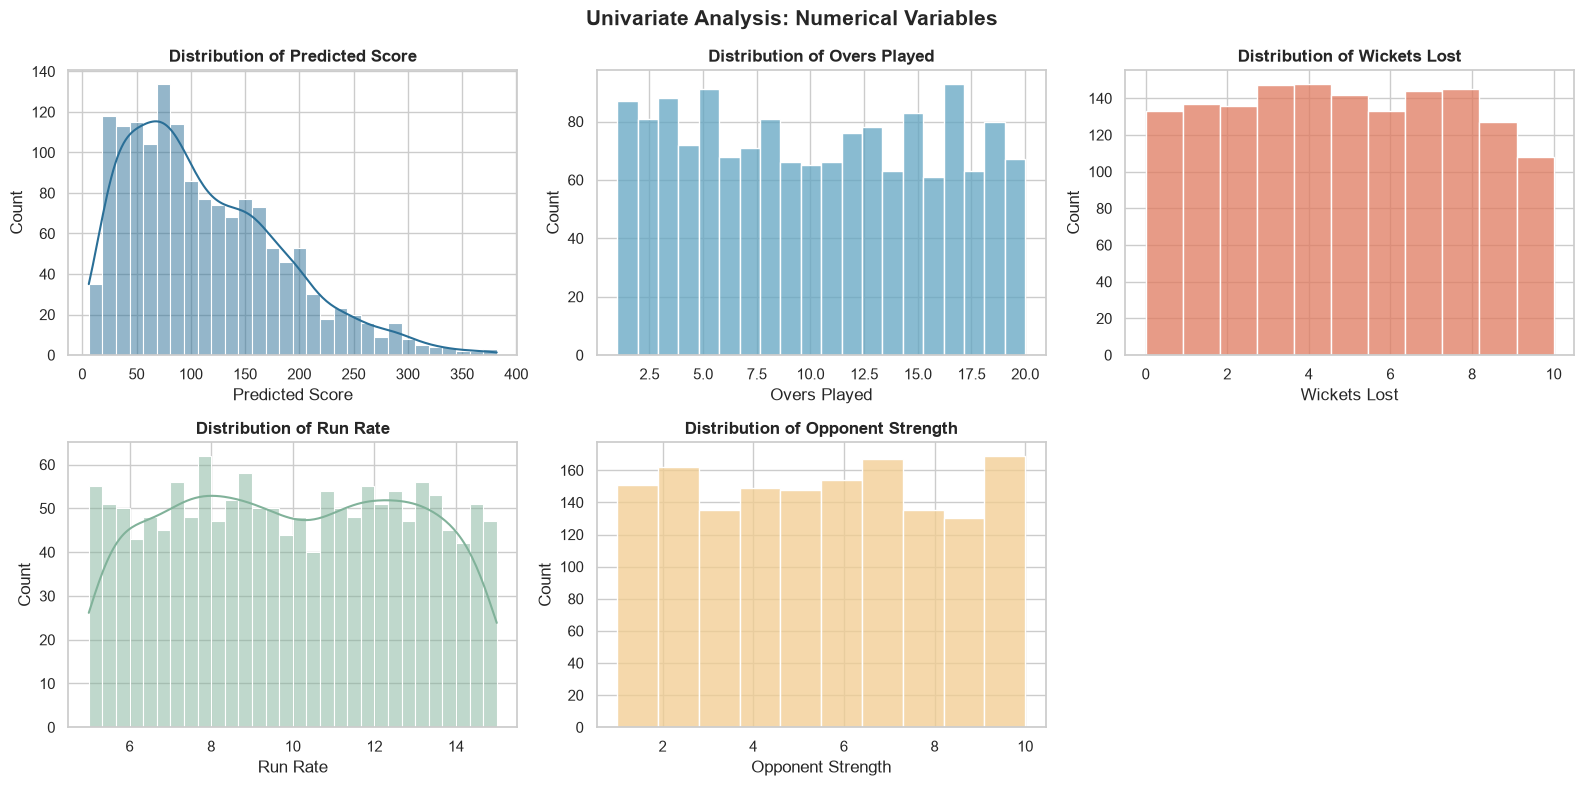

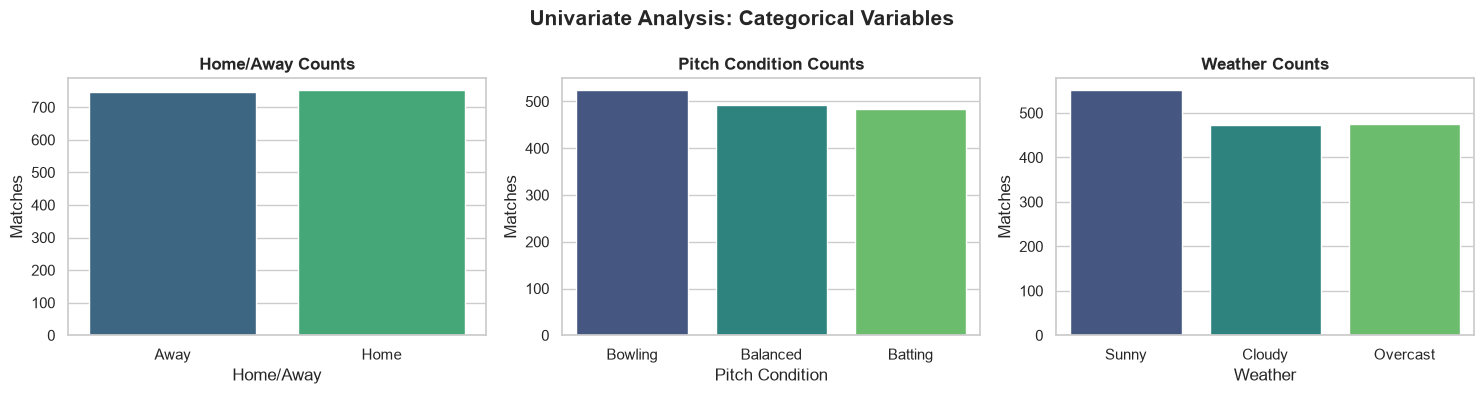

In [8]:
# ---- Univariate analysis ----
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (col, color) in zip(axes.ravel(), [(TARGET, "#2a6f97"), ("Overs Played", "#61a5c2"), ("Wickets Lost", "#e07a5f"),
                                            ("Run Rate", "#81b29a"), ("Opponent Strength", "#f2cc8f")]):
    sns.histplot(df[col], kde=col in (TARGET, "Run Rate"), bins=min(30, df[col].nunique()), color=color, ax=ax)
    ax.set_title(f"Distribution of {col}"); ax.set_xlabel(col); ax.set_ylabel("Count")
axes[1, 2].axis("off")
fig.suptitle("Univariate Analysis: Numerical Variables", fontsize=15, fontweight="bold"); fig.tight_layout()
save_fig(fig, "01_univariate_numeric.png"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, CAT_RAW):
    sns.countplot(data=df, x=col, hue=col, palette="viridis", legend=False, ax=ax)
    ax.set_title(f"{col} Counts"); ax.set_xlabel(col); ax.set_ylabel("Matches")
fig.suptitle("Univariate Analysis: Categorical Variables", fontsize=15, fontweight="bold"); fig.tight_layout()
save_fig(fig, "02_univariate_categorical.png"); plt.show()

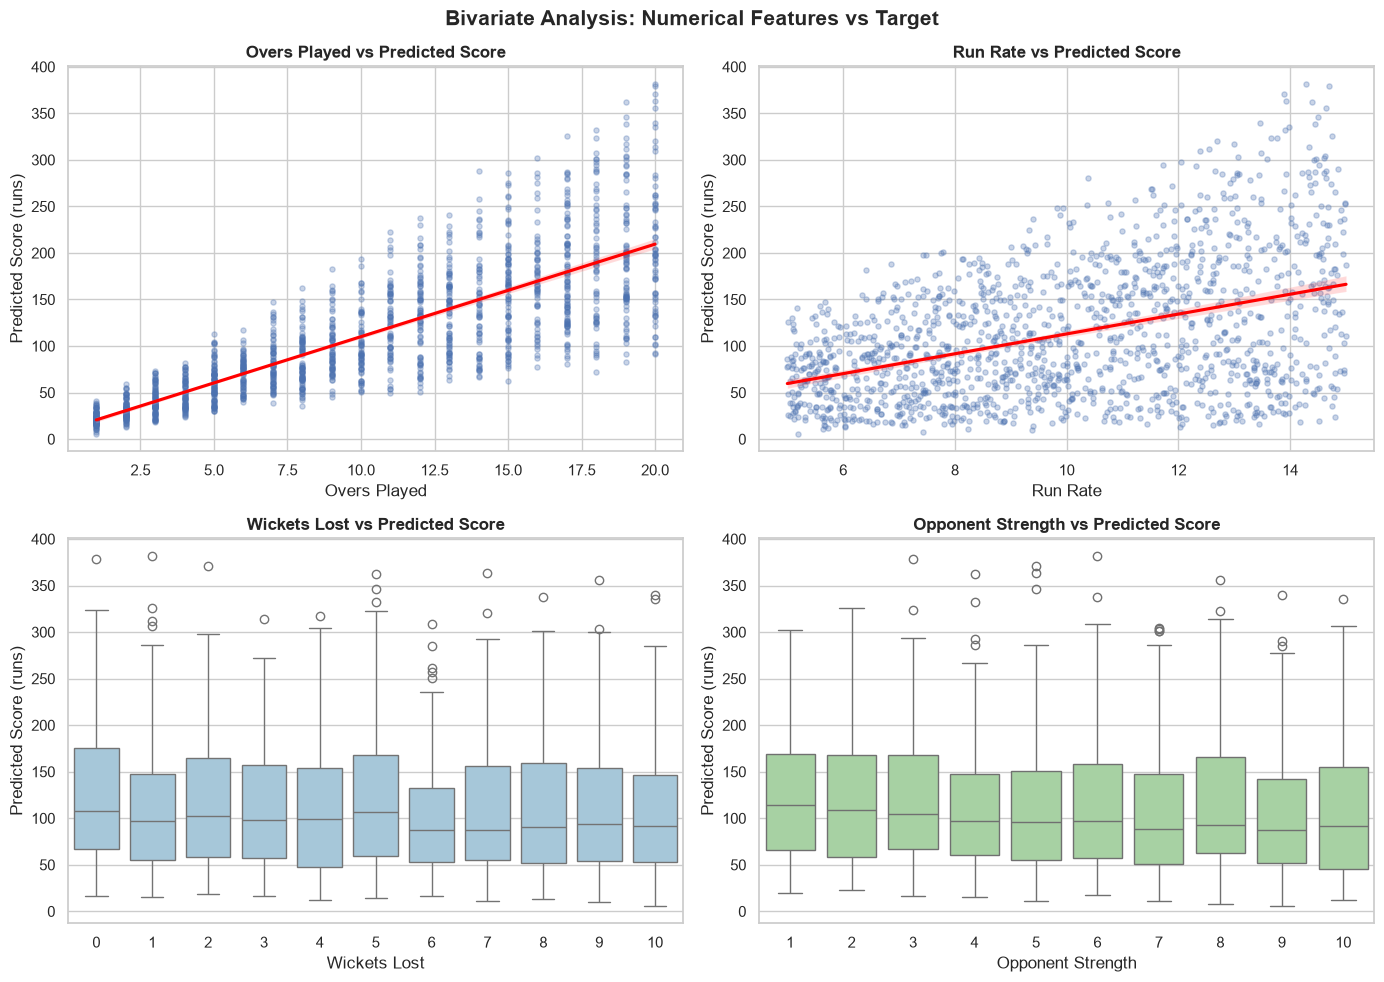

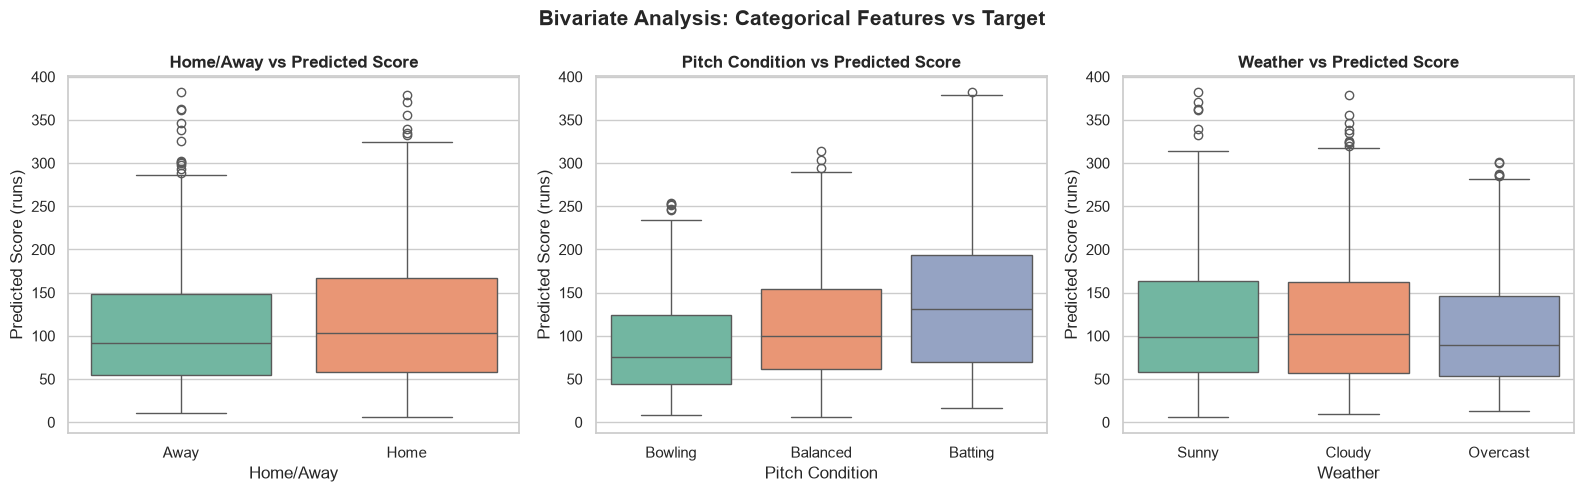

In [9]:
# ---- Bivariate analysis ----
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.regplot(data=df, x="Overs Played", y=TARGET, scatter_kws={"alpha": .3, "s": 14}, line_kws={"color": "red"}, ax=axes[0, 0]); axes[0, 0].set_title("Overs Played vs Predicted Score")
sns.regplot(data=df, x="Run Rate", y=TARGET, scatter_kws={"alpha": .3, "s": 14}, line_kws={"color": "red"}, ax=axes[0, 1]); axes[0, 1].set_title("Run Rate vs Predicted Score")
sns.boxplot(data=df, x="Wickets Lost", y=TARGET, color="#9ecae1", ax=axes[1, 0]); axes[1, 0].set_title("Wickets Lost vs Predicted Score")
sns.boxplot(data=df, x="Opponent Strength", y=TARGET, color="#a1d99b", ax=axes[1, 1]); axes[1, 1].set_title("Opponent Strength vs Predicted Score")
for ax in axes.ravel(): ax.set_ylabel("Predicted Score (runs)")
fig.suptitle("Bivariate Analysis: Numerical Features vs Target", fontsize=15, fontweight="bold"); fig.tight_layout()
save_fig(fig, "03_bivariate_numeric.png"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, CAT_RAW):
    sns.boxplot(data=df, x=col, y=TARGET, hue=col, palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{col} vs Predicted Score"); ax.set_ylabel("Predicted Score (runs)")
fig.suptitle("Bivariate Analysis: Categorical Features vs Target", fontsize=15, fontweight="bold"); fig.tight_layout()
save_fig(fig, "04_bivariate_categorical.png"); plt.show()

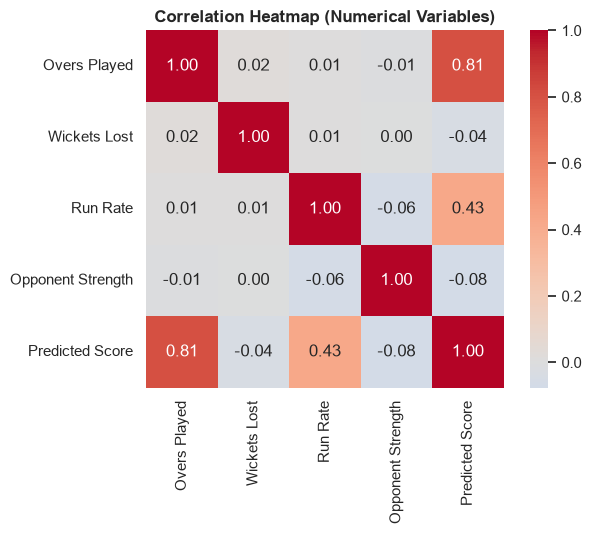

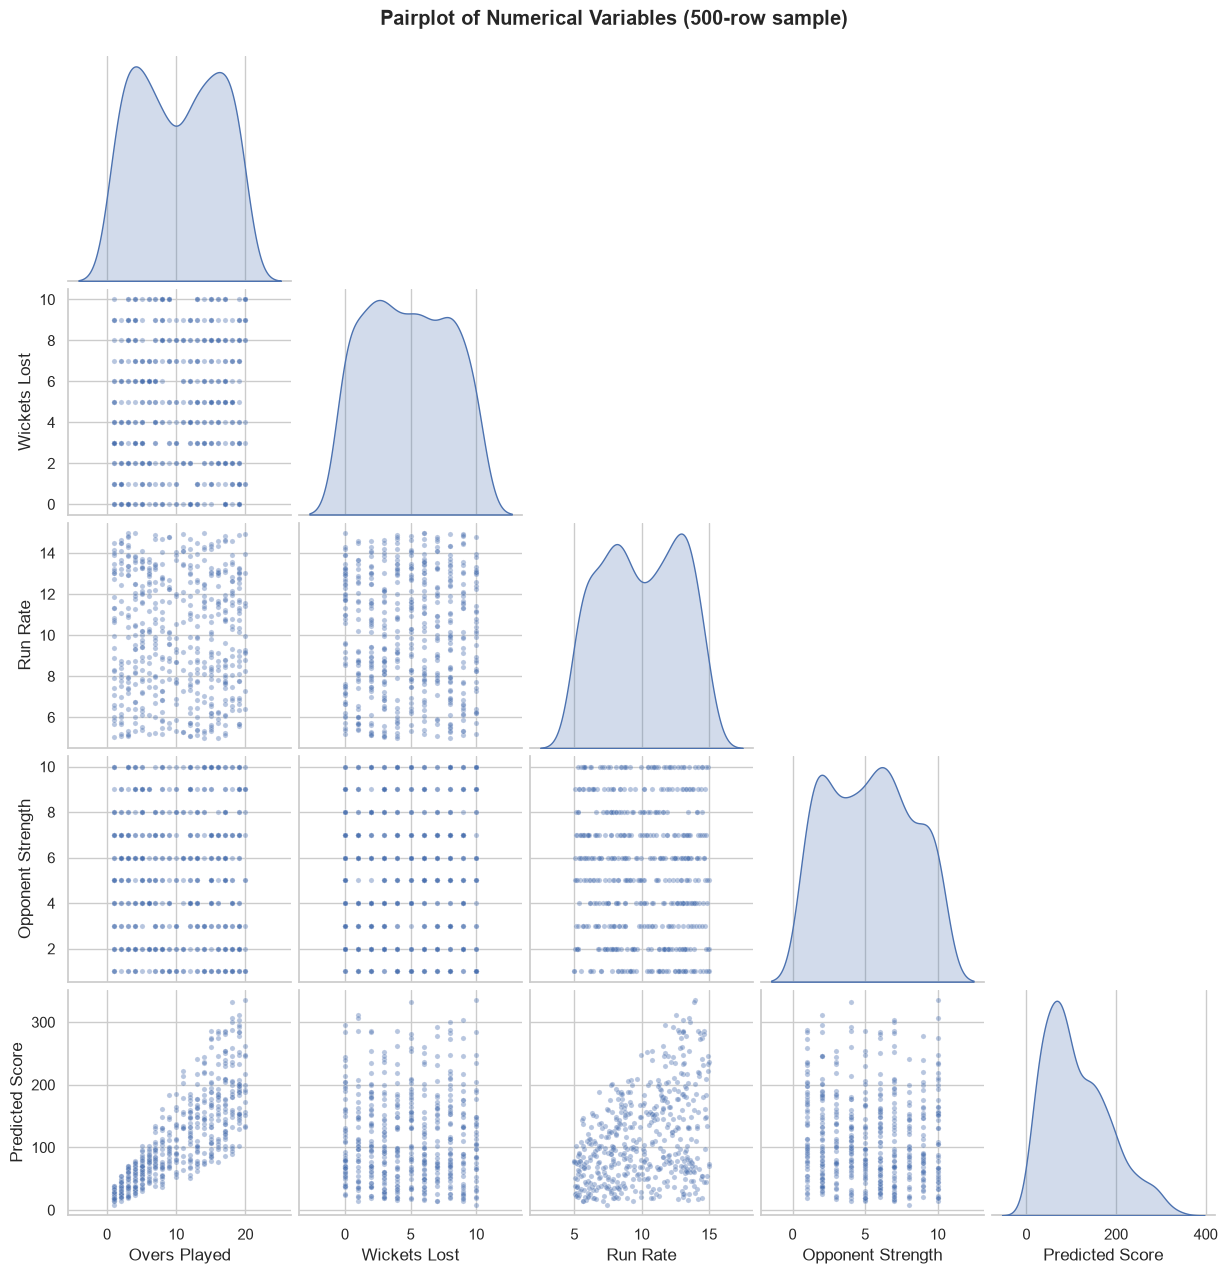

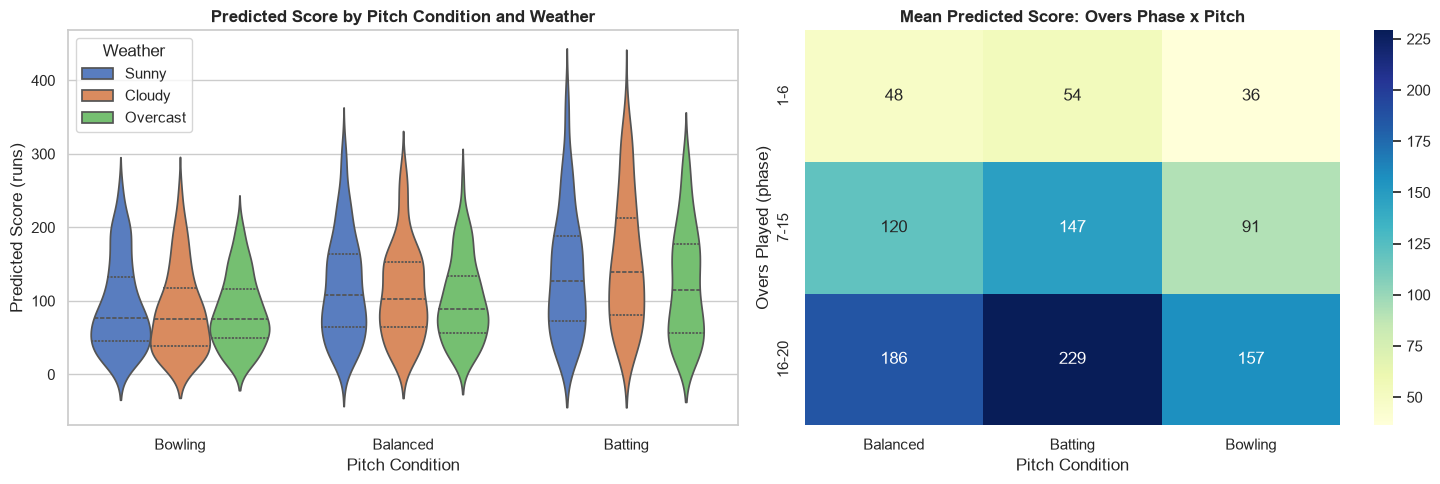

--- Grouped statistics ---


,count,mean,median,std,min,max
Home/Away,,,,,,
Away,748,107.8,92.0,68.2,11,382
Home,752,117.5,103.0,75.1,6,379


,count,mean,median,std,min,max
Pitch Condition,,,,,,
Balanced,492,111.4,100.0,64.3,6,314
Batting,484,139.8,130.5,83.9,17,382
Bowling,524,88.7,76.0,56.3,8,254


,count,mean,median,std,min,max
Weather,,,,,,
Cloudy,473,118.6,102.0,77.2,10,379
Overcast,476,103.1,89.5,62.6,13,301
Sunny,551,115.8,99.0,74.0,6,382


In [10]:
# ---- Multivariate analysis ----
num_cols_all = NUM_RAW + [TARGET]
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df[num_cols_all].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation Heatmap (Numerical Variables)"); fig.tight_layout()
save_fig(fig, "05_correlation_heatmap.png"); plt.show()

pp = sns.pairplot(df[num_cols_all].sample(500, random_state=SEED), corner=True, plot_kws={"alpha": .4, "s": 14}, diag_kind="kde")
pp.figure.suptitle("Pairplot of Numerical Variables (500-row sample)", y=1.02, fontweight="bold")
save_fig(pp.figure, "06_pairplot.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.violinplot(data=df, x="Pitch Condition", y=TARGET, hue="Weather", split=False, inner="quart", palette="muted", ax=axes[0])
axes[0].set_title("Predicted Score by Pitch Condition and Weather"); axes[0].set_ylabel("Predicted Score (runs)")
df_tmp = df.assign(Overs_Bin=pd.cut(df["Overs Played"], [0, 6, 15, 20], labels=["1-6", "7-15", "16-20"]))
pivot = df_tmp.pivot_table(index="Overs_Bin", columns="Pitch Condition", values=TARGET, aggfunc="mean", observed=True)
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[1]); axes[1].set_title("Mean Predicted Score: Overs Phase x Pitch"); axes[1].set_ylabel("Overs Played (phase)")
fig.tight_layout(); save_fig(fig, "07_violin_and_phase_heatmap.png"); plt.show()

print("--- Grouped statistics ---")
for col in CAT_RAW:
    display(df.groupby(col)[TARGET].agg(["count", "mean", "median", "std", "min", "max"]).round(1))

,feature,IQR_low,IQR_high,IQR_outliers,Z>3_outliers
0,Overs Played,-10.00,30.00,0,0
1,Wickets Lost,-7.00,17.00,0,0
2,Run Rate,0.05,19.94,0,0
3,Opponent Strength,-4.50,15.50,0,0
4,Predicted Score,-95.50,308.50,19,11


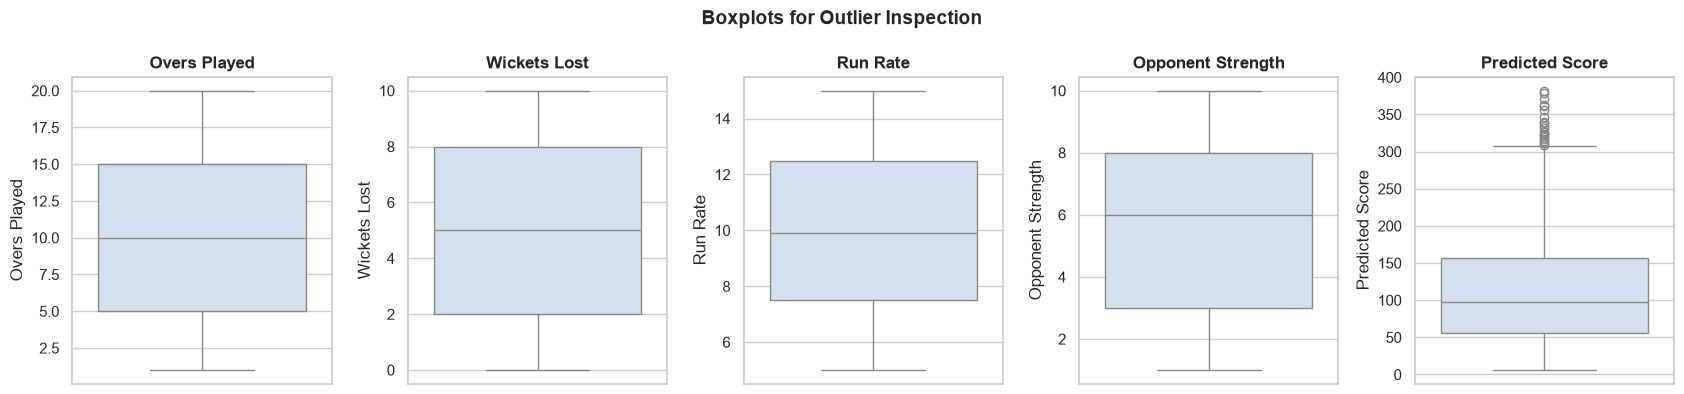

Rows whose score deviates by more than 3 standard deviations from the simple linear expectation: 15


,Match ID,Overs Played,Wickets Lost,Run Rate,Home/Away,Opponent Strength,Pitch Condition,Weather,Predicted Score,linear_residual,resid_z
1107,1108,20,1,14.29,Away,6,Batting,Sunny,382,52.402411,4.344209
1032,1033,19,5,14.39,Away,4,Batting,Sunny,362,51.463730,4.266451
540,541,20,7,13.93,Away,5,Batting,Sunny,363,49.374995,4.093425
1008,1009,20,2,13.89,Home,5,Batting,Sunny,371,49.020962,4.064098
119,120,19,6,14.66,Away,4,Bowling,Overcast,209,-45.260115,-3.745915
39,40,20,10,13.46,Home,9,Batting,Sunny,340,44.851476,3.718708
1242,1243,18,5,13.90,Home,4,Batting,Sunny,332,43.561102,3.611816
457,458,17,1,14.95,Home,1,Bowling,Overcast,199,-42.268871,-3.498128
1026,1027,19,0,13.22,Home,1,Bowling,Overcast,198,-41.891448,-3.466863
606,607,18,2,14.52,Home,10,Bowling,Overcast,197,-41.682681,-3.449569


Reading: IQR flags on Predicted Score are the high-scoring tail produced by long innings with high run rates, and are consistent with the other columns, so they are kept. Rows are only 'unusual' where the score disagrees with the inputs.


In [11]:
# ---- Outlier analysis (IQR, boxplots, Z-score). No rows are removed. ----
rows = []
for col in NUM_RAW + [TARGET]:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = np.abs(stats.zscore(df[col]))
    rows.append({"feature": col, "IQR_low": round(lo, 2), "IQR_high": round(hi, 2),
                 "IQR_outliers": int(((df[col] < lo) | (df[col] > hi)).sum()), "Z>3_outliers": int((z > 3).sum())})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 5, figsize=(17, 4))
for ax, col in zip(axes, NUM_RAW + [TARGET]):
    sns.boxplot(y=df[col], color="#cfe1f2", ax=ax); ax.set_title(col)
fig.suptitle("Boxplots for Outlier Inspection", fontsize=14, fontweight="bold"); fig.tight_layout()
save_fig(fig, "08_outlier_boxplots.png"); plt.show()

# Unusual targets relative to what the inputs imply: large residuals from a simple linear fit (diagnostic only)
dd = df.copy(); dd["linear_residual"] = resid.values; dd["resid_z"] = stats.zscore(dd["linear_residual"])
unusual = dd.loc[dd["resid_z"].abs() > 3].sort_values("resid_z", key=np.abs, ascending=False)
print(f"Rows whose score deviates by more than 3 standard deviations from the simple linear expectation: {len(unusual)}")
display(unusual.head(10))
print("Reading: IQR flags on Predicted Score are the high-scoring tail produced by long innings with high run rates, "
      "and are consistent with the other columns, so they are kept. Rows are only 'unusual' where the score disagrees with the inputs.")

In [12]:
# ---- EDA findings summary (computed) ----
pearson = df[NUM_RAW + [TARGET]].corr()[TARGET].drop(TARGET)
spearman = df[NUM_RAW + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET)
corr_table = pd.DataFrame({"Pearson": pearson, "Spearman": spearman}).round(3).sort_values("Pearson", key=np.abs, ascending=False)
print("Correlation with Predicted Score:"); display(corr_table)
cat_effect = {c: float(df.groupby(c)[TARGET].mean().max() - df.groupby(c)[TARGET].mean().min()) for c in CAT_RAW}
print("Spread of group means (max-min, runs):", {k: round(v, 1) for k, v in cat_effect.items()})
print("\nFINDINGS: strongest numeric driver =", corr_table.index[0], f"(r={corr_table.iloc[0,0]:.2f});",
      "second =", corr_table.index[1], f"(r={corr_table.iloc[1,0]:.2f}).",
      "Largest categorical spread =", max(cat_effect, key=cat_effect.get), ".",
      "Numeric inputs are nearly uncorrelated with each other, so multicollinearity is not a concern. "
      "Overs Played x Run Rate together carry most of the signal, which motivates the engineered features below.")

Correlation with Predicted Score:


,Pearson,Spearman
Overs Played,0.811,0.863
Run Rate,0.427,0.380
Opponent Strength,-0.077,-0.084
Wickets Lost,-0.040,-0.043


Spread of group means (max-min, runs): {'Home/Away': 9.7, 'Pitch Condition': 51.1, 'Weather': 15.4}

FINDINGS: strongest numeric driver = Overs Played (r=0.81); second = Run Rate (r=0.43). Largest categorical spread = Pitch Condition . Numeric inputs are nearly uncorrelated with each other, so multicollinearity is not a concern. Overs Played x Run Rate together carry most of the signal, which motivates the engineered features below.


## 5. Feature engineering module
All cricket features live in a small module (`t20_features.py`) so that **training and prediction use exactly the same code**, and the saved pipeline can be loaded independently. Features use only the input columns, never `Predicted Score`.

| Feature | Definition |
|---|---|
| `current_est_runs` | Overs Played × Run Rate (an *approximation* of runs so far) |
| `wickets_remaining`, `overs_remaining` | 10 − Wickets Lost, 20 − Overs Played |
| `scoring_phase` | Powerplay (overs 1-6), Middle (7-15), Death (16-20) |
| `run_rate_category` | low (<6), moderate (6-9), high (9-12), very_high (>12) |
| `wicket_pressure` | Wickets lost per over played |
| `remaining_innings_pct` | Overs Remaining / 20 |
| Interactions | Wickets Lost × Overs Played, Run Rate × Wickets Remaining, Overs Remaining × Run Rate |

Features that need data the file does not have (batter quality, required run rate, bowler form, venue, chronology) are **excluded**.

In [13]:
FEATURE_MODULE = r"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SNAKE = {"Overs Played": "overs_played", "Wickets Lost": "wickets_lost", "Run Rate": "run_rate",
         "Home/Away": "home_away", "Opponent Strength": "opponent_strength",
         "Pitch Condition": "pitch_condition", "Weather": "weather"}
BASE_NUM = ["overs_played", "wickets_lost", "run_rate", "opponent_strength"]
BASE_CAT = ["home_away", "pitch_condition", "weather"]
BASIC_NUM = ["current_est_runs", "wickets_remaining", "overs_remaining", "wicket_pressure", "remaining_innings_pct"]
BASIC_CAT = ["scoring_phase", "run_rate_category"]
FULL_NUM = ["wickets_x_overs", "rr_x_wickets_remaining", "overs_remaining_x_rr"]
FEATURE_SETS = ("raw", "basic", "full")


def feature_columns(feature_set):
    num, cat = list(BASE_NUM), list(BASE_CAT)
    if feature_set in ("basic", "full"):
        num += BASIC_NUM; cat += BASIC_CAT
    if feature_set == "full":
        num += FULL_NUM
    return num, cat


class CricketFeatureEngineer(BaseEstimator, TransformerMixin):
    # Turns the 7 raw input columns into the model's feature table. Stateless, so it cannot leak.
    def __init__(self, feature_set="full"):
        self.feature_set = feature_set

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("CricketFeatureEngineer expects a pandas DataFrame with the raw column names.")
        missing = [c for c in SNAKE if c not in X.columns]
        if missing:
            raise ValueError("Missing input columns: %s" % missing)
        d = X[list(SNAKE)].rename(columns=SNAKE).copy()
        for c in BASE_NUM:
            d[c] = pd.to_numeric(d[c], errors="coerce").astype(float)
        if self.feature_set in ("basic", "full"):
            o, w, rr = d["overs_played"], d["wickets_lost"], d["run_rate"]
            d["current_est_runs"] = o * rr
            d["wickets_remaining"] = 10 - w
            d["overs_remaining"] = 20 - o
            d["wicket_pressure"] = w / o.clip(lower=1)
            d["remaining_innings_pct"] = (20 - o) / 20 * 100
            phase = pd.Series(np.select([o <= 6, o <= 15], ["powerplay", "middle"], default="death"), index=d.index, dtype=object)
            phase[o.isna()] = np.nan
            d["scoring_phase"] = phase
            d["run_rate_category"] = pd.cut(rr, [-np.inf, 6, 9, 12, np.inf], labels=["low", "moderate", "high", "very_high"]).astype(object)
        if self.feature_set == "full":
            d["wickets_x_overs"] = d["wickets_lost"] * d["overs_played"]
            d["rr_x_wickets_remaining"] = d["run_rate"] * d["wickets_remaining"]
            d["overs_remaining_x_rr"] = d["overs_remaining"] * d["run_rate"]
        num, cat = feature_columns(self.feature_set)
        return d[num + cat]


def build_preprocessor(feature_set="full", scale=False):
    num, cat = feature_columns(feature_set)
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    ct = ColumnTransformer(
        [("num", Pipeline(num_steps), num),
         ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                           ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)],
        verbose_feature_names_out=False)
    ct.set_output(transform="pandas")
    return ct


def build_pipeline(model, feature_set="full", scale=False):
    return Pipeline([("fe", CricketFeatureEngineer(feature_set)),
                     ("prep", build_preprocessor(feature_set, scale)),
                     ("model", model)])
"""
with open("t20_features.py", "w") as f:
    f.write(FEATURE_MODULE)
import t20_features
importlib.reload(t20_features)
from t20_features import CricketFeatureEngineer, build_preprocessor, build_pipeline, feature_columns, FEATURE_SETS

# Validate the cricket calculations on hand-made examples
probe = pd.DataFrame([{"Overs Played": 10, "Wickets Lost": 3, "Run Rate": 8.0, "Home/Away": "Home",
                       "Opponent Strength": 5, "Pitch Condition": "Balanced", "Weather": "Sunny"}])
fe_probe = CricketFeatureEngineer("full").transform(probe).iloc[0]
assert fe_probe["current_est_runs"] == 80 and fe_probe["wickets_remaining"] == 7 and fe_probe["overs_remaining"] == 10
assert fe_probe["scoring_phase"] == "middle" and fe_probe["run_rate_category"] == "moderate"
assert fe_probe["overs_remaining_x_rr"] == 80 and fe_probe["remaining_innings_pct"] == 50
print("Feature engineering validated on a hand-checked example:"); display(fe_probe.to_frame("value").T)

Feature engineering validated on a hand-checked example:

,overs_played,wickets_lost,run_rate,opponent_strength,current_est_runs,wickets_remaining,overs_remaining,wicket_pressure,remaining_innings_pct,wickets_x_overs,rr_x_wickets_remaining,overs_remaining_x_rr,home_away,pitch_condition,weather,scoring_phase,run_rate_category
value,10.0,3.0,8.0,5.0,80.0,7.0,10.0,0.3,50.0,30.0,56.0,80.0,Home,Balanced,Sunny,middle,moderate


## 6. Data splitting (70 / 15 / 15)
Match ID is dropped. The split is random with a fixed seed. **Limitation:** the file has no dates or match ordering, so a chronological split is impossible and is not invented. Random splitting is fine for independent rows, but it would overstate performance if rows came from the same match or time period. The test set is touched only in Section 15.

In [14]:
X = df[RAW_FEATURES].copy()     # Match ID removed
y = df[TARGET].astype(float).copy()

X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.15, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.15 / 0.85, random_state=SEED)
print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test (locked): {len(X_test)}")
print("Target mean  train/val/test:", round(y_train.mean(), 1), round(y_val.mean(), 1), round(y_test.mean(), 1))
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)   # used on TRAIN only for tuning and stability

Train: 1049 | Validation: 226 | Test (locked): 225
Target mean  train/val/test: 113.2 109.4 113.1


## 7. Evaluation helpers
Regression metrics (MAE, MSE, RMSE, R², Explained Variance) plus a **custom tolerance-based accuracy**: the percentage of predictions whose absolute error is within ±5/10/15/20 runs. This is *not* classification accuracy.

In [15]:
TOLERANCES = (5, 10, 15, 20)

def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = np.abs(y_true - y_pred)
    m = {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mean_squared_error(y_true, y_pred),
         "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))), "R2": r2_score(y_true, y_pred),
         "Explained Variance": explained_variance_score(y_true, y_pred)}
    for t in TOLERANCES:
        m[f"+/-{t} Runs Accuracy (%)"] = float((err <= t).mean() * 100)   # custom tolerance accuracy
    return m

def cv_rmse(pipe, X_, y_, cv=CV):
    s = cross_val_score(pipe, X_, y_, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    return -s.mean(), s.std()

RESULTS = {}          # name -> dict(row, fitted, unfitted, stage)
def register(name, pipe_unfitted, stage, run_cv=True):
    t0 = time.time()
    fitted = clone(pipe_unfitted).fit(X_train, y_train)
    tr, va = regression_metrics(y_train, fitted.predict(X_train)), regression_metrics(y_val, fitted.predict(X_val))
    cvm, cvs = cv_rmse(pipe_unfitted, X_train, y_train) if run_cv else (np.nan, np.nan)
    row = {"Model": name, "Stage": stage, **{k: va[k] for k in va}, "Train RMSE": tr["RMSE"], "Train R2": tr["R2"],
           "CV RMSE (mean)": cvm, "CV RMSE (std)": cvs, "Fit+CV time (s)": time.time() - t0}
    RESULTS[name] = {"row": row, "fitted": fitted, "unfitted": clone(pipe_unfitted), "stage": stage}
    print(f"{name:<34} val RMSE {va['RMSE']:7.2f} | val MAE {va['MAE']:6.2f} | val R2 {va['R2']:.4f} | CV RMSE {cvm:7.2f}")

## 8. Feature-set ablation: do the engineered features actually help?
Compares `raw` (original columns), `basic` (+ cricket features) and `full` (+ interactions) with 5-fold CV on the **training set only**. The winning set is used for all later models.

In [16]:
ablation_models = {"Ridge (scaled)": (lambda: Ridge(alpha=1.0), True),
                   "RandomForest": (lambda: RandomForestRegressor(n_estimators=150, min_samples_leaf=3, random_state=SEED, n_jobs=-1), False),
                   "HistGradientBoosting": (lambda: HistGradientBoostingRegressor(random_state=SEED), False)}
abl = []
for fs in FEATURE_SETS:
    for mname, (mk, sc) in ablation_models.items():
        m, s = cv_rmse(build_pipeline(mk(), fs, sc), X_train, y_train)
        abl.append({"feature_set": fs, "model": mname, "cv_rmse": m, "cv_std": s})
abl = pd.DataFrame(abl)
abl["rank_within_model"] = abl.groupby("model")["cv_rmse"].rank()
summary = abl.groupby("feature_set").agg(mean_rank=("rank_within_model", "mean"), mean_cv_rmse=("cv_rmse", "mean")).sort_values(["mean_rank", "mean_cv_rmse"])
display(abl.pivot(index="feature_set", columns="model", values="cv_rmse").round(2)); display(summary.round(3))
FEATURE_SET = summary.index[0]
print("Selected feature set:", FEATURE_SET)

model,HistGradientBoosting,RandomForest,Ridge (scaled)
feature_set,,,
basic,4.60,7.82,12.04
full,4.75,7.94,12.03
raw,6.12,11.12,20.95


,mean_rank,mean_cv_rmse
feature_set,,
basic,1.333,8.152
full,1.667,8.239
raw,3.000,12.730


Selected feature set: basic


## 9. Baseline model comparison
Trains every requested regressor (plus a mean-predicting dummy for context) on the training set, scores on validation, and runs 5-fold CV on the training set. Unavailable optional libraries are skipped, not fatal.

In [17]:
def model_zoo():
    z = {"Dummy (predict mean)": (DummyRegressor(), False),
         "Linear Regression": (LinearRegression(), True),
         "Ridge Regression": (Ridge(alpha=1.0, random_state=SEED), True),
         "Lasso Regression": (Lasso(alpha=0.1, max_iter=20000, random_state=SEED), True),
         "Decision Tree": (DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=SEED), False),
         "Random Forest": (RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1), False),
         "Extra Trees": (ExtraTreesRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1), False),
         "Gradient Boosting": (GradientBoostingRegressor(random_state=SEED), False),
         "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=SEED), False)}
    if HAS_XGB:  z["XGBoost"] = (XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED, n_jobs=-1, verbosity=0), False)
    if HAS_LGBM: z["LightGBM"] = (LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1, n_jobs=-1), False)
    if HAS_CAT:  z["CatBoost"] = (CatBoostRegressor(iterations=400, learning_rate=0.05, depth=5, random_seed=SEED, verbose=0, allow_writing_files=False, thread_count=-1), False)
    return z

ZOO = model_zoo()
for name, (est, scale) in ZOO.items():
    register(name, build_pipeline(est, FEATURE_SET, scale), "Baseline")

Dummy (predict mean)               val RMSE   68.27 | val MAE  54.16 | val R2 -0.0032 | CV RMSE   72.87


Linear Regression                  val RMSE   11.75 | val MAE   8.38 | val R2 0.9703 | CV RMSE   12.05


Ridge Regression                   val RMSE   11.78 | val MAE   8.39 | val R2 0.9701 | CV RMSE   12.04


Lasso Regression                   val RMSE   11.61 | val MAE   8.10 | val R2 0.9710 | CV RMSE   12.07


Decision Tree                      val RMSE    8.75 | val MAE   6.36 | val R2 0.9835 | CV RMSE   10.21


Random Forest                      val RMSE    6.04 | val MAE   4.32 | val R2 0.9922 | CV RMSE    7.33


... (2 outputs left out)

HistGradientBoosting               val RMSE    3.87 | val MAE   2.57 | val R2 0.9968 | CV RMSE    4.60


XGBoost                            val RMSE    3.30 | val MAE   2.32 | val R2 0.9977 | CV RMSE    3.73


LightGBM                           val RMSE    3.39 | val MAE   2.26 | val R2 0.9975 | CV RMSE    4.33


CatBoost                           val RMSE    2.35 | val MAE   1.69 | val R2 0.9988 | CV RMSE    2.91


## 10. Hyperparameter optimization
Only the strongest candidates are tuned, with deliberately small search spaces (the dataset has ~1,000 training rows). All searches use 5-fold CV on the **training set**; validation and test sets are not used for tuning.

* Ridge / Lasso: `GridSearchCV` · Random Forest, HistGradientBoosting, XGBoost, CatBoost: `RandomizedSearchCV` · LightGBM: `Optuna` (falls back to `RandomizedSearchCV` if Optuna is missing).

In [18]:
TUNE_LOG = {}
def tune(name, est, scale, space, kind="random", n_iter=10):
    t0 = time.time()
    pipe = build_pipeline(est, FEATURE_SET, scale)
    grid = {f"model__{k}": v for k, v in space.items()}
    if kind == "grid":
        s = GridSearchCV(pipe, grid, cv=CV, scoring="neg_root_mean_squared_error", n_jobs=-1)
    else:
        s = RandomizedSearchCV(pipe, grid, n_iter=n_iter, cv=CV, scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=-1)
    s.fit(X_train, y_train)
    TUNE_LOG[name] = {"method": "GridSearchCV" if kind == "grid" else "RandomizedSearchCV", "best_params": {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v) for k, v in s.best_params_.items()}, "cv_rmse": -s.best_score_}
    print(f"{name}: best CV RMSE {-s.best_score_:.3f} ({time.time()-t0:.0f}s) {TUNE_LOG[name]['best_params']}")
    register(f"{name} (tuned)", s.best_estimator_, "Tuned")

tune("Ridge Regression", Ridge(random_state=SEED), True, {"alpha": [0.01, 0.1, 1, 10, 50, 100]}, kind="grid")
tune("Lasso Regression", Lasso(max_iter=20000, random_state=SEED), True, {"alpha": [0.001, 0.01, 0.1, 0.5, 1, 3]}, kind="grid")
tune("Random Forest", RandomForestRegressor(random_state=SEED, n_jobs=-1), False,
     {"n_estimators": randint(150, 450), "max_depth": [6, 8, 10, 14, None], "min_samples_split": randint(2, 12),
      "min_samples_leaf": randint(1, 8), "max_features": [0.5, 0.7, 1.0]}, n_iter=10)
tune("HistGradientBoosting", HistGradientBoostingRegressor(random_state=SEED), False,
     {"learning_rate": loguniform(0.02, 0.2), "max_iter": randint(100, 400), "max_leaf_nodes": randint(8, 40),
      "min_samples_leaf": randint(5, 40), "l2_regularization": loguniform(1e-3, 10)}, n_iter=10)
if HAS_XGB:
    tune("XGBoost", XGBRegressor(random_state=SEED, n_jobs=-1, verbosity=0), False,
         {"n_estimators": randint(150, 500), "max_depth": randint(2, 7), "learning_rate": loguniform(0.02, 0.2),
          "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.6, 0.4),
          "reg_alpha": loguniform(1e-3, 5), "reg_lambda": loguniform(0.1, 10)}, n_iter=10)
if HAS_CAT:
    tune("CatBoost", CatBoostRegressor(random_seed=SEED, verbose=0, allow_writing_files=False, thread_count=-1), False,
         {"iterations": randint(200, 500), "depth": randint(3, 7), "learning_rate": loguniform(0.02, 0.2),
          "l2_leaf_reg": loguniform(1, 10)}, n_iter=8)

Ridge Regression: best CV RMSE 12.044 (1s) {'alpha': 1}


Ridge Regression (tuned)           val RMSE   11.78 | val MAE   8.39 | val R2 0.9701 | CV RMSE   12.04


Lasso Regression: best CV RMSE 12.046 (1s) {'alpha': 0.01}


Lasso Regression (tuned)           val RMSE   11.72 | val MAE   8.33 | val R2 0.9704 | CV RMSE   12.05


Random Forest: best CV RMSE 7.323 (8s) {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 364}


Random Forest (tuned)              val RMSE    6.02 | val MAE   4.30 | val R2 0.9922 | CV RMSE    7.32


... (2 outputs left out)

XGBoost: best CV RMSE 3.199 (21s) {'colsample_bytree': 0.8733054075301833, 'learning_rate': 0.08147542854470236, 'max_depth': 4, 'n_estimators': 355, 'reg_alpha': 0.027958988618089223, 'reg_lambda': 0.23145798905204878, 'subsample': 0.902144564127061}


XGBoost (tuned)                    val RMSE    2.64 | val MAE   1.87 | val R2 0.9985 | CV RMSE    3.20


CatBoost: best CV RMSE 2.615 (8s) {'depth': 3, 'iterations': 457, 'l2_leaf_reg': 5.272283709671439, 'learning_rate': 0.17361318509025225}


CatBoost (tuned)                   val RMSE    2.39 | val MAE   1.75 | val R2 0.9988 | CV RMSE    2.61


In [19]:
# LightGBM: Optuna (or RandomizedSearch fallback)
if HAS_LGBM:
    if HAS_OPT:
        t0 = time.time()
        def objective(trial):
            p = dict(n_estimators=trial.suggest_int("n_estimators", 150, 500), num_leaves=trial.suggest_int("num_leaves", 6, 40),
                     max_depth=trial.suggest_int("max_depth", 3, 10), learning_rate=trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
                     colsample_bytree=trial.suggest_float("feature_fraction", 0.5, 1.0), subsample=0.8, subsample_freq=1,
                     min_child_samples=trial.suggest_int("min_child_samples", 5, 40))
            pipe = build_pipeline(LGBMRegressor(random_state=SEED, verbose=-1, n_jobs=1, **p), FEATURE_SET, False)
            return cv_rmse(pipe, X_train, y_train)[0]
        study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
        study.optimize(objective, n_trials=20, timeout=300)
        bp = dict(study.best_params); bp["colsample_bytree"] = bp.pop("feature_fraction"); bp.update(subsample=0.8, subsample_freq=1)
        TUNE_LOG["LightGBM"] = {"method": "Optuna (TPE, 20 trials)", "best_params": bp, "cv_rmse": study.best_value}
        print(f"LightGBM: best CV RMSE {study.best_value:.3f} ({time.time()-t0:.0f}s) {bp}")
        register("LightGBM (tuned)", build_pipeline(LGBMRegressor(random_state=SEED, verbose=-1, n_jobs=-1, **bp), FEATURE_SET, False), "Tuned")
    else:
        tune("LightGBM", LGBMRegressor(random_state=SEED, verbose=-1, n_jobs=-1), False,
             {"n_estimators": randint(150, 500), "num_leaves": randint(6, 40), "max_depth": randint(3, 10),
              "learning_rate": loguniform(0.02, 0.2), "colsample_bytree": uniform(0.5, 0.5)}, n_iter=10)

LightGBM: best CV RMSE 3.159 (6s) {'n_estimators': 346, 'num_leaves': 37, 'max_depth': 3, 'learning_rate': 0.10326900930504547, 'min_child_samples': 7, 'colsample_bytree': 0.8590689908319756, 'subsample': 0.8, 'subsample_freq': 1}


LightGBM (tuned)                   val RMSE    2.74 | val MAE   1.97 | val R2 0.9984 | CV RMSE    3.16


## 11. Ensemble learning: Voting and Stacking
Base learners are the four best **tuned** models by training-CV RMSE. Voting weights (equal vs inverse-CV-RMSE) are chosen by CV on the training set. Stacking uses internal 5-fold out-of-fold predictions and a Ridge meta-model, so the meta-learner never sees in-sample base predictions. Ensembles are kept only if they genuinely help.

In [20]:
tuned_names = [n for n, r in RESULTS.items() if r["stage"] == "Tuned" and not n.startswith(("Ridge", "Lasso"))]
tuned_sorted = sorted(tuned_names, key=lambda n: RESULTS[n]["row"]["CV RMSE (mean)"])[:4]
print("Ensemble base learners:", tuned_sorted)
base = [(n.replace(" (tuned)", ""), clone(RESULTS[n]["unfitted"].named_steps["model"])) for n in tuned_sorted]
cv_scores = np.array([RESULTS[n]["row"]["CV RMSE (mean)"] for n in tuned_sorted])
inv_w = list((1 / cv_scores) / (1 / cv_scores).sum())

vote_cv = {}
for label, w in {"equal": None, "inverse-CV-RMSE": inv_w}.items():
    p = build_pipeline(VotingRegressor(base, weights=w, n_jobs=1), FEATURE_SET, True)
    vote_cv[label] = cv_rmse(p, X_train, y_train)[0]
best_w_label = min(vote_cv, key=vote_cv.get)
print("Voting CV RMSE by weighting strategy:", {k: round(v, 3) for k, v in vote_cv.items()}, "->", best_w_label)
register("Voting Regressor", build_pipeline(VotingRegressor(base, weights=None if best_w_label == "equal" else inv_w, n_jobs=1), FEATURE_SET, True), "Ensemble")

stack = StackingRegressor(estimators=base, final_estimator=RidgeCV(alphas=[0.1, 1, 10]), cv=5, n_jobs=1, passthrough=False)
register("Stacking Regressor", build_pipeline(stack, FEATURE_SET, True), "Ensemble")

Ensemble base learners: ['CatBoost (tuned)', 'LightGBM (tuned)', 'XGBoost (tuned)', 'HistGradientBoosting (tuned)']


Voting CV RMSE by weighting strategy: {'equal': np.float64(2.316), 'inverse-CV-RMSE': np.float64(2.248)} -> inverse-CV-RMSE


Voting Regressor                   val RMSE    1.93 | val MAE   1.31 | val R2 0.9992 | CV RMSE    2.25


Stacking Regressor                 val RMSE    1.84 | val MAE   1.30 | val R2 0.9993 | CV RMSE    2.15


## 12. Model comparison table (validation set)
Sorted by validation RMSE, then MAE. Tolerance columns are the custom "% of predictions within ± N runs" metric.

In [21]:
metric_cols = ["MAE", "MSE", "RMSE", "R2", "Explained Variance"] + [f"+/-{t} Runs Accuracy (%)" for t in TOLERANCES]
comparison = pd.DataFrame([r["row"] for r in RESULTS.values()])
comparison = comparison.sort_values(["RMSE", "MAE"]).reset_index(drop=True)
show_cols = ["Model", "Stage"] + metric_cols + ["CV RMSE (mean)", "CV RMSE (std)", "Train RMSE"]
display(comparison[show_cols].round(3).style.background_gradient(subset=["RMSE", "MAE"], cmap="RdYlGn_r").format(precision=3))

best_single = comparison[~comparison["Stage"].eq("Ensemble")].iloc[0]
ens = comparison[comparison["Stage"].eq("Ensemble")].set_index("Model")
print(f"Best individual model by validation RMSE: {best_single['Model']} (RMSE {best_single['RMSE']:.3f})")
for n in ens.index:
    delta = ens.loc[n, "RMSE"] - best_single["RMSE"]
    print(f"{n}: validation RMSE {ens.loc[n,'RMSE']:.3f} ({'better' if delta < 0 else 'worse'} than best individual by {abs(delta):.3f})")

,Model,Stage,MAE,MSE,RMSE,R2,Explained Variance,+/-5 Runs Accuracy (%),+/-10 Runs Accuracy (%),+/-15 Runs Accuracy (%),+/-20 Runs Accuracy (%),CV RMSE (mean),CV RMSE (std),Train RMSE
0,Stacking Regressor,Ensemble,1.299,3.387,1.840,0.999,0.999,97.788,100.000,100.000,100.000,2.146,0.125,1.011
1,Voting Regressor,Ensemble,1.306,3.736,1.933,0.999,0.999,98.673,99.558,100.000,100.000,2.248,0.191,0.743
2,CatBoost,Baseline,1.689,5.525,2.351,0.999,0.999,96.018,100.000,100.000,100.000,2.912,0.216,1.461
3,CatBoost (tuned),Tuned,1.750,5.735,2.395,0.999,0.999,93.805,100.000,100.000,100.000,2.615,0.184,1.398
4,XGBoost (tuned),Tuned,1.872,6.990,2.644,0.998,0.999,95.133,99.115,99.558,100.000,3.199,0.157,0.697
5,LightGBM (tuned),Tuned,1.969,7.483,2.735,0.998,0.998,93.805,99.115,100.000,100.000,3.159,0.260,1.348
6,XGBoost,Baseline,2.318,10.880,3.298,0.998,0.998,90.265,97.788,99.558,100.000,3.726,0.326,1.306
7,HistGradientBoosting (tuned),Tuned,2.255,11.175,3.343,0.998,0.998,92.478,97.788,99.115,100.000,3.824,0.367,1.292
8,LightGBM,Baseline,2.258,11.488,3.389,0.998,0.998,92.035,98.230,98.673,100.000,4.331,0.659,1.727
9,Gradient Boosting,Baseline,2.721,12.738,3.569,0.997,0.997,85.841,98.230,100.000,100.000,4.303,0.286,2.309


Best individual model by validation RMSE: CatBoost (RMSE 2.351)
Stacking Regressor: validation RMSE 1.840 (better than best individual by 0.510)
Voting Regressor: validation RMSE 1.933 (better than best individual by 0.418)


## 13. Final model selection (validation + cross-validation only)
Composite rank = mean of the ranks for validation RMSE, validation MAE and training-CV RMSE (ties broken by validation RMSE). The Dummy baseline is excluded. Validation R² and tolerance accuracy are shown for context and consistency checks.

In [22]:
cand = comparison[comparison["Model"] != "Dummy (predict mean)"].copy()
cand["rank_val_rmse"] = cand["RMSE"].rank(); cand["rank_val_mae"] = cand["MAE"].rank(); cand["rank_cv_rmse"] = cand["CV RMSE (mean)"].rank()
cand["composite_rank"] = cand[["rank_val_rmse", "rank_val_mae", "rank_cv_rmse"]].mean(axis=1)
cand = cand.sort_values(["composite_rank", "RMSE"]).reset_index(drop=True)
display(cand[["Model", "Stage", "RMSE", "MAE", "R2", "+/-10 Runs Accuracy (%)", "CV RMSE (mean)", "CV RMSE (std)", "composite_rank"]].head(8).round(3))
FINAL_NAME = cand.loc[0, "Model"]
print("\nSELECTED FINAL MODEL (locked):", FINAL_NAME)
final_unfitted = clone(RESULTS[FINAL_NAME]["unfitted"])
best_trainfit = RESULTS[FINAL_NAME]["fitted"]          # fitted on TRAIN only; used for diagnostics on validation
val_pred = best_trainfit.predict(X_val)

,Model,Stage,RMSE,MAE,R2,+/-10 Runs Accuracy (%),CV RMSE (mean),CV RMSE (std),composite_rank
0,Stacking Regressor,Ensemble,1.840,1.299,0.999,100.000,2.146,0.125,1.000
1,Voting Regressor,Ensemble,1.933,1.306,0.999,99.558,2.248,0.191,2.000
2,CatBoost,Baseline,2.351,1.689,0.999,100.000,2.912,0.216,3.333
3,CatBoost (tuned),Tuned,2.395,1.750,0.999,100.000,2.615,0.184,3.667
4,XGBoost (tuned),Tuned,2.644,1.872,0.998,99.115,3.199,0.157,5.333
5,LightGBM (tuned),Tuned,2.735,1.969,0.998,99.115,3.159,0.260,5.667
6,XGBoost,Baseline,3.298,2.318,0.998,97.788,3.726,0.326,7.667
7,HistGradientBoosting (tuned),Tuned,3.343,2.255,0.998,97.788,3.824,0.367,7.667



SELECTED FINAL MODEL (locked): Stacking Regressor


## 14. Model validation and diagnostics (validation set, train-only fit)
Actual vs predicted, residual behaviour, cross-validation comparison, train vs validation gap and learning curve.

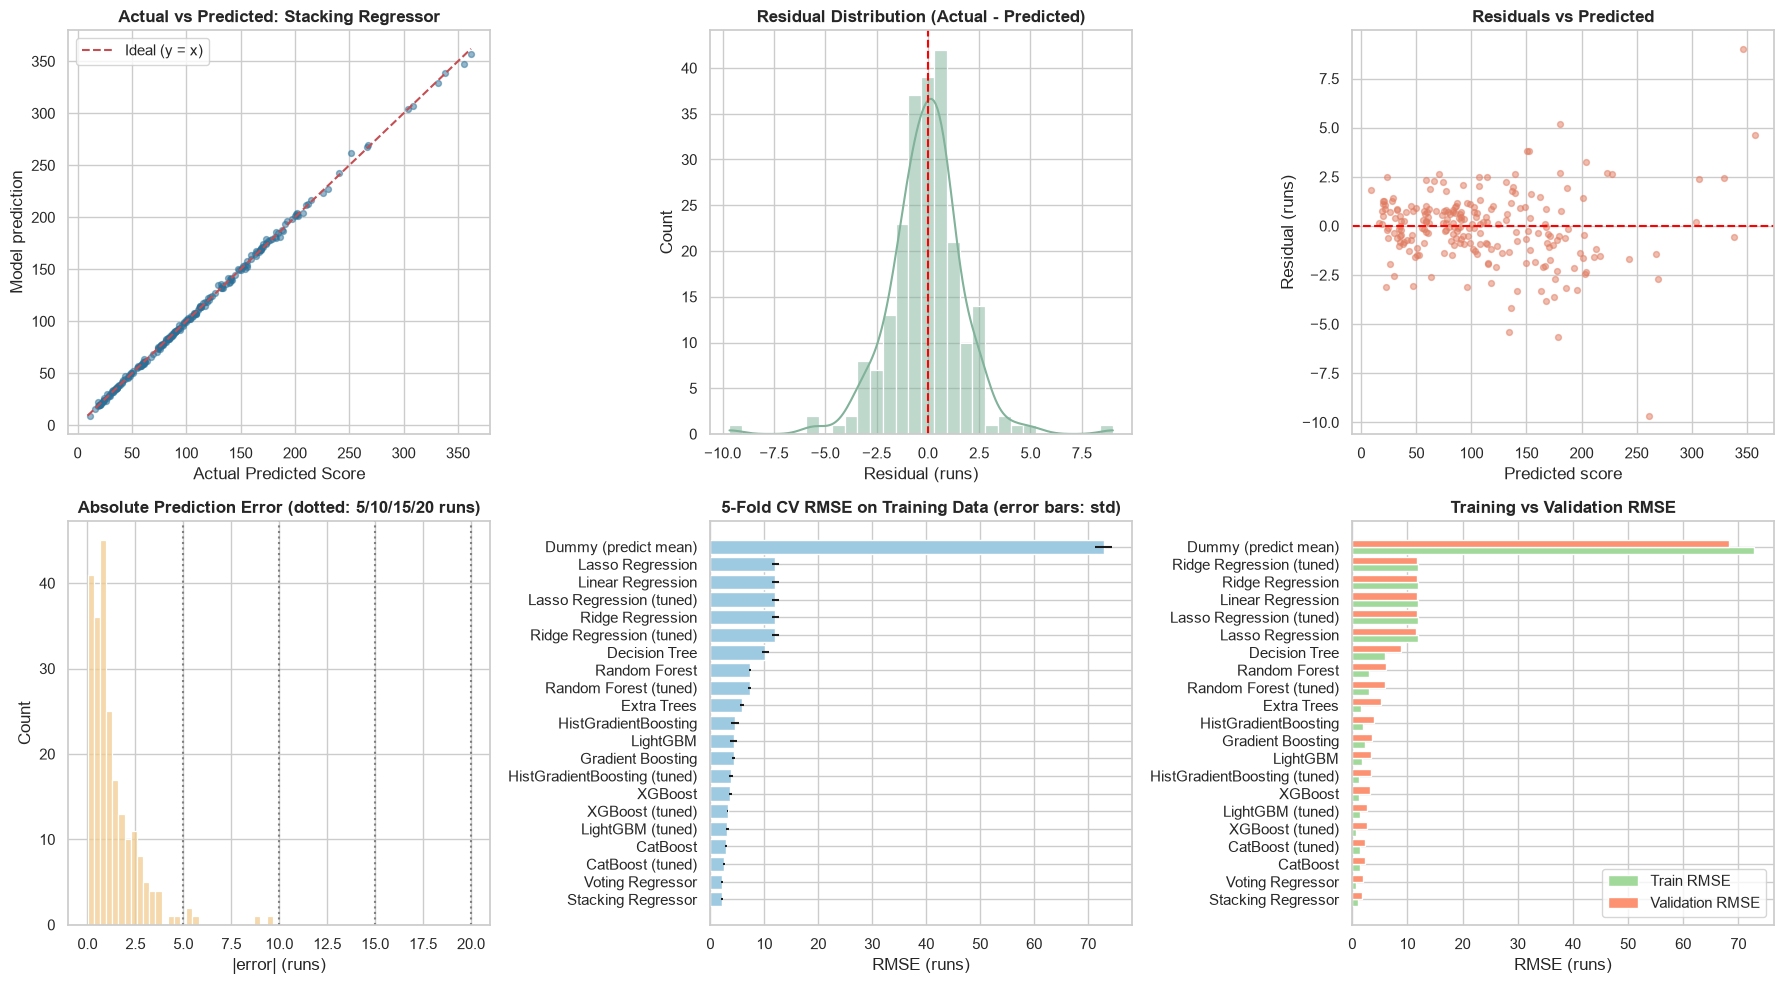

Residual mean: -0.087 | residual std: 1.838 | Shapiro-Wilk p: 0.0
MAE by predicted-score quartile (heteroscedasticity check): {Interval(9.187000000000001, 58.406, closed='right'): 0.89, Interval(58.406, 95.967, closed='right'): 0.82, Interval(95.967, 151.947, closed='right'): 1.35, Interval(151.947, 357.35, closed='right'): 2.13}

Final candidate: train RMSE 1.01 vs validation RMSE 1.84 (gap 0.83 runs).
Reading: a large train-validation gap would indicate variance/overfitting; a validation RMSE near the Dummy baseline would indicate bias/underfitting. Dummy baseline RMSE = 68.27.


In [23]:
res = y_val.values - val_pred
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
ax = axes[0, 0]; ax.scatter(y_val, val_pred, alpha=.5, s=18, color="#2a6f97"); lim = [min(y_val.min(), val_pred.min()), max(y_val.max(), val_pred.max())]
ax.plot(lim, lim, "r--", label="Ideal (y = x)"); ax.set_title(f"Actual vs Predicted: {FINAL_NAME}"); ax.set_xlabel("Actual Predicted Score"); ax.set_ylabel("Model prediction"); ax.legend()
ax = axes[0, 1]; sns.histplot(res, kde=True, bins=30, color="#81b29a", ax=ax); ax.axvline(0, color="red", ls="--"); ax.set_title("Residual Distribution (Actual - Predicted)"); ax.set_xlabel("Residual (runs)")
ax = axes[0, 2]; ax.scatter(val_pred, res, alpha=.5, s=18, color="#e07a5f"); ax.axhline(0, color="red", ls="--"); ax.set_title("Residuals vs Predicted"); ax.set_xlabel("Predicted score"); ax.set_ylabel("Residual (runs)")
ax = axes[1, 0]; sns.histplot(np.abs(res), bins=30, color="#f2cc8f", ax=ax)
for t in (5, 10, 15, 20): ax.axvline(t, color="gray", ls=":")
ax.set_title("Absolute Prediction Error (dotted: 5/10/15/20 runs)"); ax.set_xlabel("|error| (runs)")
ax = axes[1, 1]; order = comparison.sort_values("CV RMSE (mean)"); ax.barh(order["Model"], order["CV RMSE (mean)"], xerr=order["CV RMSE (std)"], color="#9ecae1")
ax.set_title("5-Fold CV RMSE on Training Data (error bars: std)"); ax.set_xlabel("RMSE (runs)")
ax = axes[1, 2]; o2 = comparison.sort_values("RMSE"); yy = np.arange(len(o2))
ax.barh(yy - .2, o2["Train RMSE"], .4, label="Train RMSE", color="#a1d99b"); ax.barh(yy + .2, o2["RMSE"], .4, label="Validation RMSE", color="#fc9272")
ax.set_yticks(yy); ax.set_yticklabels(o2["Model"]); ax.set_title("Training vs Validation RMSE"); ax.set_xlabel("RMSE (runs)"); ax.legend()
fig.tight_layout(); save_fig(fig, "09_validation_diagnostics.png"); plt.show()

print("Residual mean:", round(res.mean(), 3), "| residual std:", round(res.std(), 3), "| Shapiro-Wilk p:", round(stats.shapiro(res)[1], 4))
bins = pd.qcut(pd.Series(val_pred), 4, duplicates="drop")
print("MAE by predicted-score quartile (heteroscedasticity check):", pd.Series(np.abs(res)).groupby(bins.values, observed=True).mean().round(2).to_dict())
gap = comparison.set_index("Model").loc[FINAL_NAME]
print(f"\nFinal candidate: train RMSE {gap['Train RMSE']:.2f} vs validation RMSE {gap['RMSE']:.2f} (gap {gap['RMSE']-gap['Train RMSE']:.2f} runs).")
print("Reading: a large train-validation gap would indicate variance/overfitting; a validation RMSE near the Dummy baseline would indicate bias/underfitting. "
      f"Dummy baseline RMSE = {comparison.set_index('Model').loc['Dummy (predict mean)','RMSE']:.2f}.")

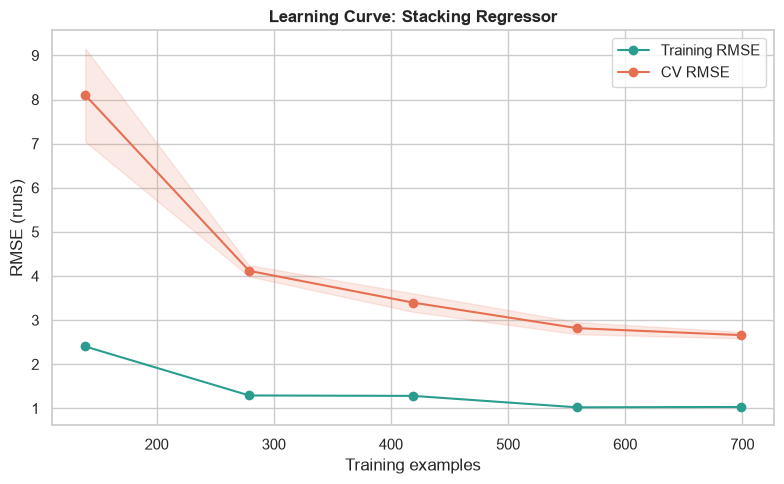

(63s)  CV RMSE still falling with more data = more data would help; flat = near the noise floor.


In [24]:
# Learning curve on the training portion only (3-fold to keep it cheap)
t0 = time.time()
sizes, tr_sc, va_sc = learning_curve(clone(final_unfitted), X_train, y_train, cv=KFold(3, shuffle=True, random_state=SEED),
                                     train_sizes=np.linspace(0.2, 1.0, 5), scoring="neg_root_mean_squared_error", n_jobs=-1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sizes, -tr_sc.mean(1), "o-", label="Training RMSE", color="#2a9d8f"); ax.plot(sizes, -va_sc.mean(1), "o-", label="CV RMSE", color="#e76f51")
ax.fill_between(sizes, -va_sc.mean(1) - va_sc.std(1), -va_sc.mean(1) + va_sc.std(1), alpha=.15, color="#e76f51")
ax.set_title(f"Learning Curve: {FINAL_NAME}"); ax.set_xlabel("Training examples"); ax.set_ylabel("RMSE (runs)"); ax.legend()
fig.tight_layout(); save_fig(fig, "10_learning_curve.png"); plt.show(); print(f"({time.time()-t0:.0f}s)  CV RMSE still falling with more data = more data would help; flat = near the noise floor.")

## 15. Final training and single test-set evaluation
The model is locked. It is **refit on train + validation** and evaluated **once** on the untouched test set. Cross-validation on train + validation gives a stability estimate and out-of-fold residuals for the prediction interval.

FINAL MODEL: Stacking Regressor   (feature set: basic)

=== FINAL TEST RESULTS (untouched test set, evaluated once) ===
MAE                          1.349
MSE                          3.531
RMSE                         1.879
R2                           0.999
Explained Variance           0.999
+/-5 Runs Accuracy (%)      96.000
+/-10 Runs Accuracy (%)    100.000
+/-15 Runs Accuracy (%)    100.000
+/-20 Runs Accuracy (%)    100.000

Context: mean-predictor baseline test RMSE = 70.90, R2 = -0.000
Cross-validation on train+validation (mean +/- std): {'rmse': '2.065 +/- 0.147', 'mae': '1.426 +/- 0.100', 'r2': '0.999 +/- 0.000'}
Validation (train-only fit) RMSE 1.840 vs final test RMSE 1.879:  consistent


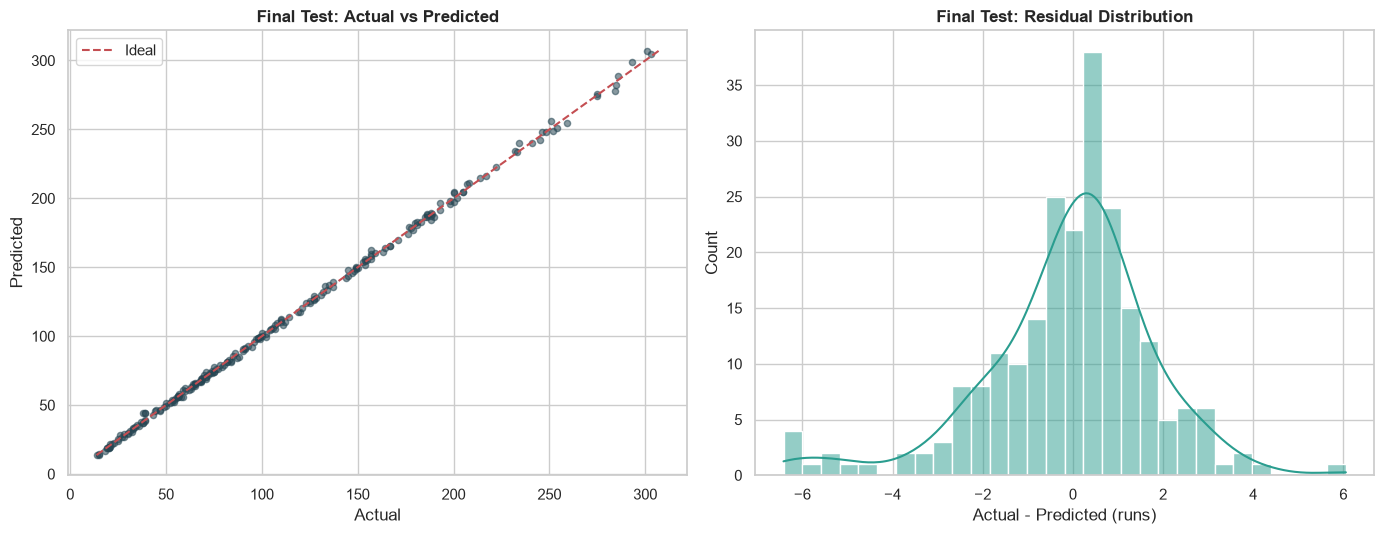

In [25]:
final_model = clone(final_unfitted).fit(X_trainval, y_trainval)
test_pred = final_model.predict(X_test)
test_metrics = regression_metrics(y_test, test_pred)          # <-- the one and only test evaluation
dummy_test = regression_metrics(y_test, DummyRegressor().fit(X_trainval, y_trainval).predict(X_test))

cvr = cross_validate(clone(final_unfitted), X_trainval, y_trainval, cv=CV, n_jobs=-1,
                     scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
cv_summary = {k: (float(np.mean(np.abs(cvr[f"test_{k}"]))), float(np.std(cvr[f"test_{k}"]))) for k in ("rmse", "mae", "r2")}

print(f"FINAL MODEL: {FINAL_NAME}   (feature set: {FEATURE_SET})")
print("\n=== FINAL TEST RESULTS (untouched test set, evaluated once) ===")
print(pd.Series(test_metrics).round(3).to_string())
print(f"\nContext: mean-predictor baseline test RMSE = {dummy_test['RMSE']:.2f}, R2 = {dummy_test['R2']:.3f}")
print("Cross-validation on train+validation (mean +/- std):", {k: f"{m:.3f} +/- {s:.3f}" for k, (m, s) in cv_summary.items()})
vr = RESULTS[FINAL_NAME]["row"]
print(f"Validation (train-only fit) RMSE {vr['RMSE']:.3f} vs final test RMSE {test_metrics['RMSE']:.3f}: ", "consistent" if abs(vr['RMSE'] - test_metrics['RMSE']) < 2 * cv_summary['rmse'][1] + 1 else "different, check for split noise")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(y_test, test_pred, alpha=.55, s=20, color="#264653"); lim = [min(y_test.min(), test_pred.min()), max(y_test.max(), test_pred.max())]
axes[0].plot(lim, lim, "r--", label="Ideal"); axes[0].set_title("Final Test: Actual vs Predicted"); axes[0].set_xlabel("Actual"); axes[0].set_ylabel("Predicted"); axes[0].legend()
sns.histplot(y_test.values - test_pred, kde=True, bins=30, color="#2a9d8f", ax=axes[1]); axes[1].set_title("Final Test: Residual Distribution"); axes[1].set_xlabel("Actual - Predicted (runs)")
fig.tight_layout(); save_fig(fig, "11_final_test_results.png"); plt.show()

## 16. Explainability
Permutation importance (on raw input columns, validation set, train-only fit), native importance and SHAP from the best tree-based model. These describe what the **model** relies on in this dataset, not causal effects in cricket.

,feature,permutation_importance_rmse_increase,std
0,Overs Played,81.621,3.059
2,Run Rate,48.146,2.300
5,Pitch Condition,26.975,1.358
6,Weather,9.762,0.458
1,Wickets Lost,4.419,0.204
4,Opponent Strength,2.443,0.164
3,Home/Away,-0.003,0.004


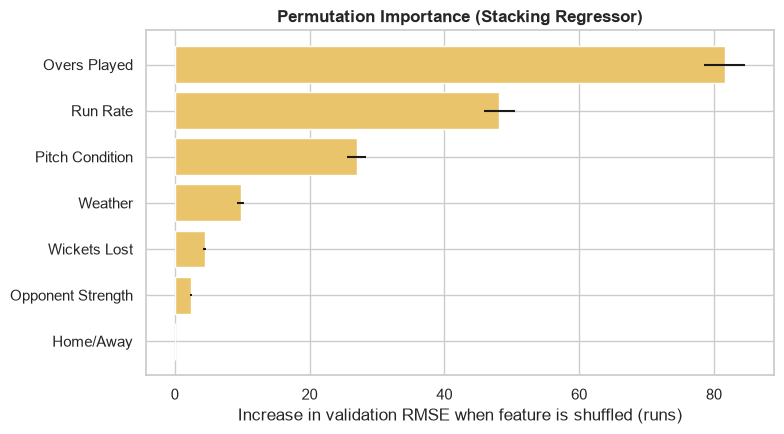

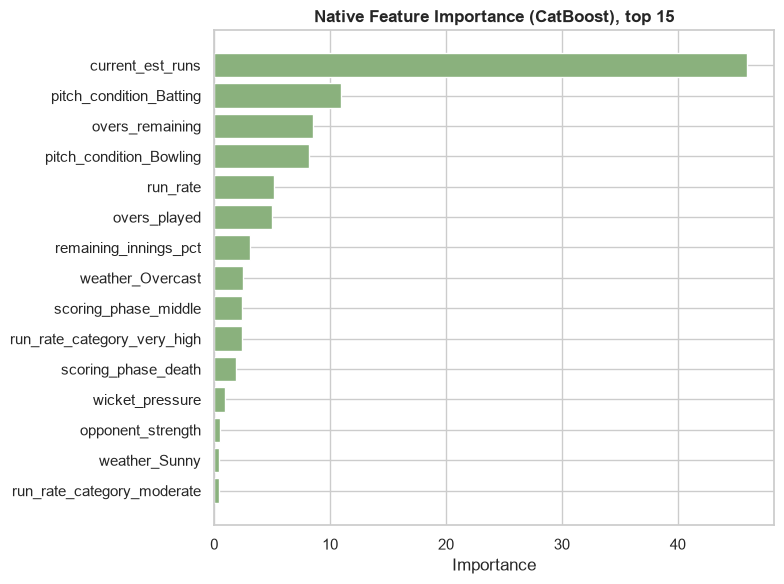

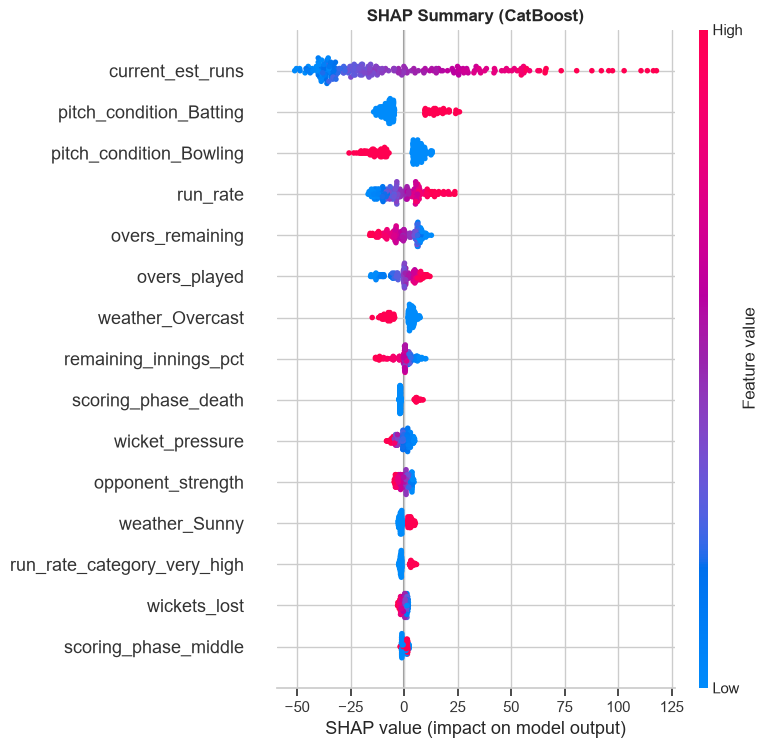

Mean |SHAP| top features: {'current_est_runs': 31.93, 'pitch_condition_Batting': 9.84, 'pitch_condition_Bowling': 9.55, 'run_rate': 8.04, 'overs_remaining': 6.12, 'overs_played': 5.47}
(Native importance and SHAP use CatBoost, the best tree-based model, because the selected final model is 'Stacking Regressor'.)

Interpretation: the most influential raw input is 'Overs Played', then 'Run Rate'. Features near zero importance carry little usable signal in this dataset. Importance is not causation.


In [26]:
pi = permutation_importance(best_trainfit, X_val, y_val, n_repeats=20, random_state=SEED, scoring="neg_root_mean_squared_error", n_jobs=-1)
perm_df = pd.DataFrame({"feature": X_val.columns, "permutation_importance_rmse_increase": pi.importances_mean, "std": pi.importances_std}).sort_values("permutation_importance_rmse_increase", ascending=False)
display(perm_df.round(3))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(perm_df["feature"][::-1], perm_df["permutation_importance_rmse_increase"][::-1], xerr=perm_df["std"][::-1], color="#e9c46a")
ax.set_title(f"Permutation Importance ({FINAL_NAME})"); ax.set_xlabel("Increase in validation RMSE when feature is shuffled (runs)")
fig.tight_layout(); save_fig(fig, "12_permutation_importance.png"); plt.show()

# Best tree model supported by SHAP
tree_pref = [n for n in comparison["Model"] if any(k in n for k in ("XGBoost", "LightGBM", "CatBoost", "Random Forest", "Extra Trees", "Gradient Boosting")) and "Hist" not in n]
native_df = pd.DataFrame(columns=["feature", "native_importance"])
if tree_pref:
    tn = tree_pref[0]; tp = RESULTS[tn]["fitted"]; Xv = tp[:-1].transform(X_val); mdl = tp.named_steps["model"]
    feats = list(Xv.columns)
    imp = getattr(mdl, "feature_importances_", None)
    if imp is not None:
        native_df = pd.DataFrame({"feature": feats, "native_importance": np.asarray(imp, float)}).sort_values("native_importance", ascending=False)
        fig, ax = plt.subplots(figsize=(8, 6)); top = native_df.head(15)
        ax.barh(top["feature"][::-1], top["native_importance"][::-1], color="#8ab17d"); ax.set_title(f"Native Feature Importance ({tn}), top 15"); ax.set_xlabel("Importance")
        fig.tight_layout(); save_fig(fig, "13_native_importance.png"); plt.show()
    if HAS_SHAP:
        try:
            import shap
            sv = shap.TreeExplainer(mdl).shap_values(Xv)
            plt.figure(); shap.summary_plot(sv, Xv, show=False, max_display=15); plt.title(f"SHAP Summary ({tn})")
            save_fig(plt.gcf(), "14_shap_summary.png"); plt.show()
            shap_imp = pd.Series(np.abs(sv).mean(0), index=feats).sort_values(ascending=False)
            print("Mean |SHAP| top features:", shap_imp.head(6).round(2).to_dict())
        except Exception as e:
            print("[skip] SHAP failed gracefully:", type(e).__name__, e)
    print(f"(Native importance and SHAP use {tn}, the best tree-based model, because the selected final model is '{FINAL_NAME}'.)")
top_raw = perm_df.iloc[0]["feature"]
print(f"\nInterpretation: the most influential raw input is '{top_raw}', then '{perm_df.iloc[1]['feature']}'. "
      "Features near zero importance carry little usable signal in this dataset. Importance is not causation.")

## 17. Prediction uncertainty and the prediction function
The interval is **empirical**: it uses absolute out-of-fold residuals (5-fold on train + validation) and a finite-sample quantile at 90%. Its real coverage is **checked on the test set**. It is a typical-error band, not a probability guarantee, and errors here may grow with the score, so the band is an average. No "confidence percentage" is shown.

In [27]:
oof = cross_val_predict(clone(final_unfitted), X_trainval, y_trainval, cv=CV, n_jobs=-1)
abs_res = np.sort(np.abs(y_trainval.values - oof))
alpha = 0.10; k = int(np.ceil((len(abs_res) + 1) * (1 - alpha))) - 1
INTERVAL_HALF_WIDTH = float(abs_res[min(k, len(abs_res) - 1)])
coverage = float(np.mean(np.abs(y_test.values - test_pred) <= INTERVAL_HALF_WIDTH) * 100)
print(f"90% empirical interval half-width: +/- {INTERVAL_HALF_WIDTH:.1f} runs | observed test coverage: {coverage:.1f}% (target ~90%)")

DATA_RANGES = {"overs": (1, 20), "wickets": (0, 10), "strength": (1, 10),
               "run_rate": (float(df["Run Rate"].min()), float(df["Run Rate"].max()))}
VALID = {"home_away": ["Home", "Away"], "pitch_condition": ["Batting", "Bowling", "Balanced"], "weather": ["Sunny", "Cloudy", "Overcast"]}

def predict_t20_score(overs_played, wickets_lost, run_rate, home_away, opponent_strength, pitch_condition, weather, model=None):
    """Predict the final T20 innings score. Validates inputs, then uses the SAME saved feature-engineering + preprocessing pipeline."""
    model = model or final_model
    if not 1 <= overs_played <= 20: raise ValueError("overs_played must be between 1 and 20")
    if not 0 <= wickets_lost <= 10 or int(wickets_lost) != wickets_lost: raise ValueError("wickets_lost must be an integer from 0 to 10")
    if not 0 < run_rate <= 36: raise ValueError("run_rate must be positive (and at most 36)")
    if not 1 <= opponent_strength <= 10: raise ValueError("opponent_strength must be between 1 and 10")
    for name, val in (("home_away", home_away), ("pitch_condition", pitch_condition), ("weather", weather)):
        if val not in VALID[name]: raise ValueError(f"{name} must be one of {VALID[name]}")
    row = pd.DataFrame([{"Overs Played": overs_played, "Wickets Lost": wickets_lost, "Run Rate": run_rate, "Home/Away": home_away,
                         "Opponent Strength": opponent_strength, "Pitch Condition": pitch_condition, "Weather": weather}])
    raw = float(model.predict(row)[0])
    notes = []
    lo_rr, hi_rr = DATA_RANGES["run_rate"]
    if not lo_rr <= run_rate <= hi_rr: notes.append(f"run rate outside the training range ({lo_rr:.1f}-{hi_rr:.1f}); extrapolation, treat with caution")
    return {"predicted_score": int(round(max(raw, 0))), "raw_prediction": raw,
            "interval_90": (int(round(max(raw - INTERVAL_HALF_WIDTH, 0))), int(round(raw + INTERVAL_HALF_WIDTH))), "notes": notes}

demo = predict_t20_score(10, 3, 8.0, "Home", 5, "Balanced", "Sunny"); print("Demo prediction:", demo)
# Consistency check: function output must equal direct pipeline output on a real test row
r0 = X_test.iloc[[0]]; direct = float(final_model.predict(r0)[0])
via_fn = predict_t20_score(*r0.iloc[0].tolist())["raw_prediction"]
assert abs(direct - via_fn) < 1e-9, "prediction function and pipeline disagree"
print("Prediction function matches the pipeline exactly.")

90% empirical interval half-width: +/- 3.0 runs | observed test coverage: 91.1% (target ~90%)
Demo prediction: {'predicted_score': 100, 'raw_prediction': 100.30323285329277, 'interval_90': (97, 103), 'notes': []}


Prediction function matches the pipeline exactly.


## 18. Interactive T20 score predictor
Uses `ipywidgets` when available, with a command-line style fallback.

In [28]:
def render_prediction(out):
    return out

def launch_predictor():
    lo_rr, hi_rr = DATA_RANGES["run_rate"]
    if HAS_WIDGETS:
        import ipywidgets as W
        from IPython.display import display, clear_output
        style = {"description_width": "150px"}; lay = W.Layout(width="480px")
        w_over = W.IntSlider(value=10, min=1, max=20, description="Overs Played", style=style, layout=lay)
        w_wkt = W.IntSlider(value=3, min=0, max=10, description="Wickets Lost", style=style, layout=lay)
        w_rr = W.FloatSlider(value=round((lo_rr + hi_rr) / 2, 1), min=round(lo_rr, 1), max=round(hi_rr, 1), step=0.1, description="Run Rate", style=style, layout=lay)
        w_ha = W.ToggleButtons(options=VALID["home_away"], description="Home/Away", style=style)
        w_opp = W.IntSlider(value=5, min=1, max=10, description="Opponent Strength", style=style, layout=lay)
        w_pitch = W.Dropdown(options=VALID["pitch_condition"], value="Balanced", description="Pitch Condition", style=style, layout=lay)
        w_wx = W.Dropdown(options=VALID["weather"], value="Sunny", description="Weather", style=style, layout=lay)
        btn = W.Button(description="Predict Final Score", button_style="success", icon="bolt"); out = W.Output()
        def on_click(_):
            with out:
                clear_output()
                try:
                    r = predict_t20_score(w_over.value, w_wkt.value, w_rr.value, w_ha.value, w_opp.value, w_pitch.value, w_wx.value)
                    print(f"Estimated final score: {r['predicted_score']} runs")
                    print(f"Typical-error band (90% empirical): {r['interval_90'][0]} to {r['interval_90'][1]} runs")
                    print(f"Final test performance of '{FINAL_NAME}': MAE {test_metrics['MAE']:.2f} | RMSE {test_metrics['RMSE']:.2f} | R2 {test_metrics['R2']:.3f}")
                    for n in r["notes"]: print("Note:", n)
                except ValueError as e:
                    print("Invalid input:", e)
        btn.on_click(on_click)
        display(W.VBox([W.HTML("<h3>T20 Score Predictor</h3>"), w_over, w_wkt, w_rr, w_ha, w_opp, w_pitch, w_wx, btn, out]))
    else:
        print("ipywidgets unavailable: using text input.")
        try:
            r = predict_t20_score(int(input("Overs Played (1-20): ")), int(input("Wickets Lost (0-10): ")), float(input("Run Rate: ")),
                                  input("Home/Away (Home/Away): "), int(input("Opponent Strength (1-10): ")),
                                  input("Pitch Condition (Batting/Bowling/Balanced): "), input("Weather (Sunny/Cloudy/Overcast): "))
            print("Estimated final score:", r["predicted_score"], "| band:", r["interval_90"])
        except (ValueError, EOFError) as e:
            print("Input error:", e)

launch_predictor()

## 19. Export: models, metadata, results, plots, ZIP
Saves the model, preprocessing, complete pipeline, metadata and result tables with Joblib/JSON/CSV, then verifies that the saved pipeline loads and reproduces predictions.

In [29]:
def jsonable(o):
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o

# Core artifacts
joblib.dump(final_model.named_steps["model"], os.path.join(MODELS_DIR, "best_t20_model.pkl"))
joblib.dump(final_model[:-1], os.path.join(MODELS_DIR, "t20_preprocessing_pipeline.pkl"))
joblib.dump(final_model, os.path.join(MODELS_DIR, "t20_prediction_pipeline.pkl"))
# NOTE: t20_features.py (written in Section 5) must stay next to the notebook: the pickles reference it.

feature_names = list(final_model[:-1].transform(X_test.iloc[:1]).columns)
metadata = {
    "project": "T20 Cricket Match Score Prediction", "created_utc": time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime()), "random_seed": SEED,
    "final_model": FINAL_NAME, "feature_set": FEATURE_SET, "input_columns": RAW_FEATURES, "model_feature_names": feature_names, "target": TARGET,
    "split": {"train": len(X_train), "validation": len(X_val), "test": len(X_test), "final_fit_rows": len(X_trainval)},
    "final_test_metrics": test_metrics, "cross_validation_train_val": {k: {"mean": m, "std": s} for k, (m, s) in cv_summary.items()},
    "validation_metrics_of_final_model": {k: vr[k] for k in metric_cols},
    "prediction_interval": {"level": 0.90, "half_width_runs": INTERVAL_HALF_WIDTH, "observed_test_coverage_pct": coverage, "method": "empirical quantile of out-of-fold absolute residuals"},
    "hyperparameter_tuning": TUNE_LOG, "valid_categories": VALID, "input_ranges": DATA_RANGES,
    "data_quality": quality_report, "software": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "sklearn": __import__("sklearn").__version__},
    "warning": "Target-generation method is unverified and some rows are internally inconsistent; results describe this dataset and are not evidence of real-world T20 forecasting accuracy.",
}
with open(os.path.join(RESULTS_DIR, "model_metadata.json"), "w") as f: json.dump(jsonable(metadata), f, indent=2)

# Result tables
eval_tbl = comparison[show_cols].copy(); eval_tbl.insert(2, "Evaluation Set", "Validation")
final_row = {"Model": FINAL_NAME, "Stage": "Final (train+val refit)", "Evaluation Set": "Test (untouched)", **test_metrics,
             "CV RMSE (mean)": cv_summary["rmse"][0], "CV RMSE (std)": cv_summary["rmse"][1]}
eval_tbl = pd.concat([eval_tbl, pd.DataFrame([final_row])], ignore_index=True)
eval_tbl.to_csv(os.path.join(RESULTS_DIR, "model_evaluation_results.csv"), index=False)

avp = pd.DataFrame({"Actual": y_test.values, "Predicted": test_pred.round(2), "Error": (y_test.values - test_pred).round(2),
                    "Abs_Error": np.abs(y_test.values - test_pred).round(2),
                    "Interval_Low_90": np.maximum(test_pred - INTERVAL_HALF_WIDTH, 0).round(1), "Interval_High_90": (test_pred + INTERVAL_HALF_WIDTH).round(1)}, index=X_test.index)
pd.concat([X_test, avp], axis=1).to_csv(os.path.join(RESULTS_DIR, "actual_vs_predicted.csv"))

fi = perm_df.rename(columns={"permutation_importance_rmse_increase": "importance"}).assign(method="permutation (raw input, validation)")
if len(native_df): fi = pd.concat([fi, native_df.rename(columns={"native_importance": "importance"}).assign(method="native (best tree model, model-input columns)")], ignore_index=True)
fi.to_csv(os.path.join(RESULTS_DIR, "feature_importance.csv"), index=False)

# Verify that artifacts load independently and reproduce predictions
loaded = joblib.load(os.path.join(MODELS_DIR, "t20_prediction_pipeline.pkl"))
assert np.allclose(loaded.predict(X_test), test_pred), "reloaded pipeline does not reproduce predictions"
_ = joblib.load(os.path.join(MODELS_DIR, "best_t20_model.pkl")); _ = joblib.load(os.path.join(MODELS_DIR, "t20_preprocessing_pipeline.pkl"))
print("Artifacts saved and reload-verified (predictions identical).")

Artifacts saved and reload-verified (predictions identical).


## 19A. Model artifact compatibility and integrity checks
Loads the saved pipeline in a **fresh Python process** (as a user would) and verifies: loading, feature consistency, prediction reproducibility against `results/actual_vs_predicted.csv`, metadata consistency and library versions.

In [30]:
check_script = "\n".join([
    "import sys, json, joblib, numpy as np, pandas as pd",
    "sys.path.insert(0, '.')",
    "pipe = joblib.load('models/t20_prediction_pipeline.pkl')",
    "model = joblib.load('models/best_t20_model.pkl')",
    "d = pd.read_csv('results/actual_vs_predicted.csv', index_col=0)",
    "raw = d[['Overs Played', 'Wickets Lost', 'Run Rate', 'Home/Away', 'Opponent Strength', 'Pitch Condition', 'Weather']]",
    "print(json.dumps({'pred': pipe.predict(raw).tolist(), 'features': list(pipe[:-1].transform(raw.iloc[:1]).columns), 'model_type': type(model).__name__}))",
])
proc = subprocess.run([sys.executable, "-c", check_script], capture_output=True, text=True)
assert proc.returncode == 0, "Fresh-process load FAILED:\n" + proc.stderr[-1500:]
out = json.loads(proc.stdout.strip().splitlines()[-1])
saved = pd.read_csv(os.path.join(RESULTS_DIR, "actual_vs_predicted.csv"), index_col=0)
meta = json.load(open(os.path.join(RESULTS_DIR, "model_metadata.json")))
rmse_csv = float(np.sqrt(np.mean((saved["Actual"] - np.array(out["pred"])) ** 2)))
checks_ok = {
    "pipeline + model load in a fresh process": True,
    "prediction reproducibility (|diff| < 0.01 vs saved CSV)": bool(np.allclose(out["pred"], saved["Predicted"], atol=0.01)),
    "feature names match metadata": out["features"] == meta["model_feature_names"],
    "metadata test RMSE matches recomputed RMSE": abs(meta["final_test_metrics"]["RMSE"] - rmse_csv) < 0.01,
    "metadata test RMSE matches results CSV final row": abs(pd.read_csv(os.path.join(RESULTS_DIR, "model_evaluation_results.csv")).iloc[-1]["RMSE"] - meta["final_test_metrics"]["RMSE"]) < 1e-6,
    "final model name consistent": meta["final_model"] == FINAL_NAME,
    "scikit-learn version matches metadata": meta["software"]["sklearn"] == __import__("sklearn").__version__,
}
display(pd.Series(checks_ok, name="passed").to_frame())
assert all(checks_ok.values()), "An artifact integrity check failed"
print("All artifact checks passed. Final stored test RMSE =", round(meta["final_test_metrics"]["RMSE"], 3), "| saved model type:", out["model_type"])

,passed
pipeline + model load in a fresh process,True
prediction reproducibility (|diff| < 0.01 vs saved CSV),True
feature names match metadata,True
metadata test RMSE matches recomputed RMSE,True
metadata test RMSE matches results CSV final row,True
final model name consistent,True
scikit-learn version matches metadata,True


All artifact checks passed. Final stored test RMSE = 1.879 | saved model type: StackingRegressor


In [31]:
ZIP_NAME = "T20_Cricket_ML_Project_Results.zip"
nb_name = "T20_Cricket_Score_Prediction_Advanced.ipynb"
with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in (MODELS_DIR, RESULTS_DIR, VIZ_DIR, DATASET_DIR):
        for root, _, fs in os.walk(folder):
            for fn in fs: z.write(os.path.join(root, fn))
    for extra in ("t20_features.py", nb_name, "README.md", "requirements.txt", "environment.yml", "runtime_versions.json"):
        if os.path.exists(extra): z.write(extra)
print("ZIP created:", ZIP_NAME, f"({os.path.getsize(ZIP_NAME)/1e6:.2f} MB)")
if IN_COLAB: files.download(ZIP_NAME)

ZIP created: T20_Cricket_ML_Project_Results.zip (4.55 MB)


## 20. Final project report
Generated from this run's actual results. Nothing here is typed in by hand.

In [32]:
def fmt(v): return f"{v:.2f}"
tuned_rows = {k: v["method"] for k, v in TUNE_LOG.items()}
top_feats = ", ".join(perm_df["feature"].head(3).tolist())
report = f"""
================================ FINAL PROJECT REPORT ================================
Project            : T20 Cricket Match Score Prediction Using Advanced ML and Ensemble Learning
Dataset            : {df.shape[0]} rows x {df.shape[1]} columns (Match ID excluded from modelling); missing values: {quality_report['missing_values']}, duplicates: {quality_report['duplicate_rows']}
Features used      : {', '.join(RAW_FEATURES)}
Engineered set     : '{FEATURE_SET}' chosen by CV ablation ({', '.join(feature_columns(FEATURE_SET)[0][4:] + feature_columns(FEATURE_SET)[1][3:])})
Preprocessing      : feature engineering + median/mode imputation + one-hot encoding (+ scaling for linear/ensemble models), all inside Pipelines fitted on training data only
Split              : {len(X_train)} train / {len(X_val)} validation / {len(X_test)} test (random, seed {SEED}); final model refit on {len(X_trainval)} rows
Models trained     : {', '.join(m for m in comparison['Model'] if '(tuned)' not in m)}
Tuning             : {tuned_rows}
Best model         : {FINAL_NAME}
Validation         : RMSE {fmt(vr['RMSE'])} | MAE {fmt(vr['MAE'])} | R2 {vr['R2']:.3f}
Cross-validation   : RMSE {fmt(cv_summary['rmse'][0])} +/- {fmt(cv_summary['rmse'][1])} | MAE {fmt(cv_summary['mae'][0])} | R2 {cv_summary['r2'][0]:.3f}  (train+val, 5-fold)
FINAL TEST         : MAE {fmt(test_metrics['MAE'])} | RMSE {fmt(test_metrics['RMSE'])} | R2 {test_metrics['R2']:.3f}
Tolerance accuracy : +/-5: {test_metrics['+/-5 Runs Accuracy (%)']:.1f}% | +/-10: {test_metrics['+/-10 Runs Accuracy (%)']:.1f}% | +/-15: {test_metrics['+/-15 Runs Accuracy (%)']:.1f}% | +/-20: {test_metrics['+/-20 Runs Accuracy (%)']:.1f}%   (custom metric)
Mean-predictor baseline test RMSE: {fmt(dummy_test['RMSE'])}
Prediction interval: 90% empirical +/-{INTERVAL_HALF_WIDTH:.1f} runs, observed test coverage {coverage:.1f}%
Most important inputs (permutation): {top_feats}
Limitations        : target-generation method unverified ({quality_report['target_below_runs_so_far_pct']}% of rows have estimated current runs > final score); possibly formula-generated; no chronology so random split only;
                     accuracy relative to genuine T20 matches is unknown; interval is an average band although errors may vary with score; importance is not causation.
Future improvements: real ball-by-ball data (venue, batters, bowlers, required rate), time-based validation, quantile or conformalized heteroscedastic intervals, calibration against real innings.
=======================================================================================
"""
print(report)
with open(os.path.join(RESULTS_DIR, "final_report.txt"), "w") as f: f.write(report)
print("Final report saved to", os.path.join(RESULTS_DIR, "final_report.txt"))


================================ FINAL PROJECT REPORT ================================
Project            : T20 Cricket Match Score Prediction Using Advanced ML and Ensemble Learning
Dataset            : 1500 rows x 9 columns (Match ID excluded from modelling); missing values: 0, duplicates: 0
Features used      : Overs Played, Wickets Lost, Run Rate, Home/Away, Opponent Strength, Pitch Condition, Weather
Engineered set     : 'basic' chosen by CV ablation (current_est_runs, wickets_remaining, overs_remaining, wicket_pressure, remaining_innings_pct, scoring_phase, run_rate_category)
Preprocessing      : feature engineering + median/mode imputation + one-hot encoding (+ scaling for linear/ensemble models), all inside Pipelines fitted on training data only
Split              : 1049 train / 226 validation / 225 test (random, seed 42); final model refit on 1275 rows
Models trained     : Stacking Regressor, Voting Regressor, CatBoost, XGBoost, LightGBM, Gradient Boosting, HistGradientBoosti